# Fintual: Fintual Card
Integrantes: Iair Chistik, Francisco Cisternas y Agustín Rosales

In [1]:
# Librerias 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuraciones de visualización
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
sns.set_theme(style="whitegrid")

In [2]:
# Carga de los datos inicales
diccionario = pd.read_csv("diccionario_datos_2026.csv")
fintual_percepcion = pd.read_csv("fintual_perception_dataset_2026.csv")
usuarios = pd.read_csv("fintual_users_dataset_2026.csv")
caracteristicas = pd.read_csv("user_demographics_2026.csv")

### EDA DE DIAGNOSTICO
El objetivo de realizar un EDA en esta fase es diagnosticar el estado en el que se encuentran las bases de datos para encontrar anomalias como datos fuera de rango, valores nulos, duplicados, errores de digitacio, etc. Los objetivos son:
- Dimensiones
- Valores duplicados
- Valores nulos 
- Anomalias de digitación 
- Valores fuera de rango 
- Valores atipicos

In [3]:
# Inspección de los tablas (Dimensiones)
base_datos = {
    "usuarios": usuarios,
    "caracteristicas": caracteristicas,
    "fintual_percepcion": fintual_percepcion
}
for nombre, tablas in base_datos.items():
    filas, columnas = tablas.shape
    print(f"El dataset '{nombre}' tiene {filas} filas y {columnas} columnas.")

El dataset 'usuarios' tiene 12025 filas y 6 columnas.
El dataset 'caracteristicas' tiene 12000 filas y 11 columnas.
El dataset 'fintual_percepcion' tiene 21000 filas y 12 columnas.


In [4]:
# Usuarios unicos 
usuarios_unicos = usuarios['user_id'].nunique()
print(f"Usuarios unicos: {usuarios_unicos}")
usuarios_unicos_caracteristicas = caracteristicas['user_id'].nunique()
print(f"Usuarios unicos en caracteristicas: {usuarios_unicos_caracteristicas}")
usuarios_unicos_percepcion = fintual_percepcion['user_id'].nunique()
print(f"Usuarios unicos en percepcion: {usuarios_unicos_percepcion}")

Usuarios unicos: 12000
Usuarios unicos en caracteristicas: 12000
Usuarios unicos en percepcion: 3000


In [5]:
# Estadisticos usuarios
usuarios.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"11,840.00",33.61,10.17,0.00,25.00,33.00,40.00,150.00
total_invested,"12,025.00","8,106,127.96","13,929,064.99","15,500.00","302,300.00","2,824,300.00","9,637,000.00","239,386,000.00"
risk_tolerance,"11,647.00",3.22,1.21,0.00,2.00,3.00,4.00,5.00
months_active,"12,025.00",32.54,22.28,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"11,581.00",20.97,10.01,1.00,13.00,21.00,29.00,47.00


In [6]:
# Estadisticos caracteristicas
caracteristicas.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,12000,12000,FTL_00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,11881,16,Metropolitana de Santiago,6830,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,11772,3,Masculino,6204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tramo_ingreso,11009,5,$1.200.001 - $2.500.000,3059,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ocupacion,12000,5,Dependiente,7707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
banco_principal,12000,12,Banco de Chile,2340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tiene_tarjeta_credito,12000,2,Sí,7989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_tarjetas_credito,"12,000.00",NaN,NaN,NaN,1.20,1.07,0.00,0.00,1.00,2.00,4.00
billetera_digital_principal,12000,5,Ninguna,4444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gasto_mensual_tarjetas_clp,"12,000.00",NaN,NaN,NaN,"1,155,643.58","1,046,950.30","48,000.00","440,000.00","848,000.00","1,519,000.00","14,602,000.00"


In [7]:
# Estadisticos percepcion
fintual_percepcion.describe().T

,count,mean,std,min,25%,50%,75%,max
ease_of_use,"20,202.00",5.57,1.17,1.00,5.00,6.00,7.00,7.00
fees_transparency,"20,016.00",4.75,1.39,1.00,4.00,5.00,6.00,7.00
investment_options,"19,882.00",4.54,1.44,1.00,4.00,5.00,6.00,7.00
customer_support,"19,779.00",4.68,1.18,1.00,4.00,5.00,5.00,7.00
mobile_experience,"20,168.00",5.63,1.15,1.00,5.00,6.00,7.00,7.00
educational_content,"20,029.00",4.26,1.40,1.00,3.00,4.00,5.00,7.00
trust_security,"20,228.00",5.27,1.13,1.00,5.00,5.00,6.00,7.00
returns_performance,"19,521.00",4.67,1.23,1.00,4.00,5.00,6.00,7.00
social_impact,"19,360.00",4.28,1.21,1.00,3.00,4.00,5.00,7.00
innovation,"20,020.00",5.20,1.35,1.00,4.00,5.00,6.00,7.00


In [8]:
# Detalle especifico de los nulos por base y columna
def resumen_nulos(diccionario_dfs):
    for nombre, df in diccionario_dfs.items():
        conteo_nulos = df.isnull().sum()
        porcentaje_nulos = (df.isnull().mean() * 100).round(2)
        
        # Armamos el DataFrame resumen
        resumen = pd.DataFrame({
            "Nulos": conteo_nulos,
            "% Nulos": porcentaje_nulos
        })
        
        print(f"-------- Nulos en '{nombre}' (Total filas: {len(df)}) --------")
        display(resumen)

resumen_nulos(base_datos)


-------- Nulos en 'usuarios' (Total filas: 12025) --------


,Nulos,% Nulos
user_id,0,0.00
age,185,1.54
total_invested,0,0.00
risk_tolerance,378,3.14
months_active,0,0.00
app_sessions_month,444,3.69


-------- Nulos en 'caracteristicas' (Total filas: 12000) --------


,Nulos,% Nulos
user_id,0,0.00
region,119,0.99
genero,228,1.90
tramo_ingreso,991,8.26
ocupacion,0,0.00
banco_principal,0,0.00
tiene_tarjeta_credito,0,0.00
n_tarjetas_credito,0,0.00
billetera_digital_principal,0,0.00
gasto_mensual_tarjetas_clp,0,0.00


-------- Nulos en 'fintual_percepcion' (Total filas: 21000) --------


,Nulos,% Nulos
user_id,0,0.00
brand,0,0.00
ease_of_use,798,3.80
fees_transparency,984,4.69
investment_options,1118,5.32
customer_support,1221,5.81
mobile_experience,832,3.96
educational_content,971,4.62
trust_security,772,3.68
returns_performance,1479,7.04


In [9]:
# Edades registradas que están fuera de 18 a 110
edades_invalidas = usuarios[usuarios['age'].notnull() & ~usuarios['age'].between(18, 110)]
print(f"Registros con edad inválida/imposible (<18 o >110): {len(edades_invalidas)}")
display(edades_invalidas[['user_id', 'age', 'months_active', 'total_invested']])

# Tolerancia de riesgo fuera de 1 a 5
tolerancia_invalidas = usuarios[usuarios['risk_tolerance'].notnull() & ~usuarios['risk_tolerance'].between(1, 5)]
print(f"Registros con tolerancia de riesgo inválida (fuera de 1 a 5): {len(tolerancia_invalidas)}")
display(tolerancia_invalidas[['user_id', 'risk_tolerance', 'age', 'months_active', 'total_invested']].head(10))

# Chequeo adicional de consistencia temporal: edad estimada al momento de registrarse (age - months_active/12 < 18)
usuarios_unicos_temp = usuarios.drop_duplicates(subset='user_id')
edades_validas_temp = usuarios_unicos_temp[usuarios_unicos_temp['age'].between(18, 110)].copy()
edades_validas_temp['edad_al_registro'] = edades_validas_temp['age'] - (edades_validas_temp['months_active'] / 12.0)
menores_al_registro = edades_validas_temp[edades_validas_temp['edad_al_registro'] < 18]
print(f"Usuarios con edad actual válida (>=18) pero edad estimada al registro < 18 años: {len(menores_al_registro)}")

Registros con edad inválida/imposible (<18 o >110): 15


,user_id,age,months_active,total_invested
931,FTL_00930,17.00,66,28936800
1383,FTL_01382,150.00,62,15895500
1578,FTL_01576,0.00,33,3524500
2206,FTL_02203,17.00,6,193500
2545,FTL_02540,17.00,45,1562800
3519,FTL_03510,17.00,12,135200
4190,FTL_04179,17.00,12,292800
4197,FTL_04186,7.00,48,1864300
5316,FTL_05303,3.00,68,17026600
5457,FTL_05443,17.00,67,74111900


Registros con tolerancia de riesgo inválida (fuera de 1 a 5): 70


,user_id,risk_tolerance,age,months_active,total_invested
240,FTL_00241,0.00,36.00,56,70450700
388,FTL_00389,0.00,30.00,56,27615500
987,FTL_00986,0.00,21.00,4,228900
998,FTL_00997,0.00,23.00,11,32700
1154,FTL_01153,0.00,26.00,8,105300
1182,FTL_01181,0.00,36.00,17,5196900
1214,FTL_01213,0.00,56.00,60,14196800
1498,FTL_01497,0.00,19.00,14,153500
2015,FTL_02013,0.00,30.00,26,3549800
2116,FTL_02113,0.00,38.00,38,7275800


Usuarios con edad actual válida (>=18) pero edad estimada al registro < 18 años: 263


In [10]:
# Duplicados en demografía y percepción
dup_demo = caracteristicas['user_id'].duplicated().sum()
dup_perc = fintual_percepcion.duplicated(subset=['user_id', 'brand']).sum()
print(f"Duplicados de user_id en demografía: {dup_demo}")
print(f"Duplicados (user_id, brand) en percepción: {dup_perc}")

Duplicados de user_id en demografía: 0
Duplicados (user_id, brand) en percepción: 0


In [11]:
# Consistencia entre tiene_tarjeta_credito y n_tarjetas_credito
dice_no_pero_tiene = ((caracteristicas['tiene_tarjeta_credito'] == 'No') &
                      (caracteristicas['n_tarjetas_credito'] > 0)).sum()
dice_si_pero_cero = ((caracteristicas['tiene_tarjeta_credito'] == 'Sí') &
                     (caracteristicas['n_tarjetas_credito'] == 0)).sum()
print(f"'No' con n_tarjetas > 0: {dice_no_pero_tiene}")
print(f"'Sí' con n_tarjetas = 0: {dice_si_pero_cero}")

# Rango de las notas de percepción (debe ser 1 a 7)
cols_percepcion = fintual_percepcion.columns.drop(['user_id', 'brand'])
print(f"Rango de percepción: min={fintual_percepcion[cols_percepcion].min().min()}, "
      f"max={fintual_percepcion[cols_percepcion].max().max()}")

'No' con n_tarjetas > 0: 0
'Sí' con n_tarjetas = 0: 0
Rango de percepción: min=1.0, max=7.0


In [12]:
# Categorías inconsistentes en variables de texto
for col in ['genero', 'ocupacion', 'banco_principal', 'region',
            'billetera_digital_principal', 'tramo_ingreso', 'tiene_tarjeta_credito']:
    print(f"--- {col} ({caracteristicas[col].nunique()} categorías) ---")
    print(caracteristicas[col].value_counts(dropna=False).to_string(), "\n")

--- genero (3 categorías) ---
genero
Masculino                   6204
Femenino                    5330
Otro / Prefiere no decir     238
NaN                          228 

--- ocupacion (5 categorías) ---
ocupacion
Dependiente      7707
Estudiante       1697
Independiente    1611
Empresario        935
Jubilado           50 

--- banco_principal (12 categorías) ---
banco_principal
Banco de Chile     2340
BancoEstado        2268
Santander          1813
BCI                1478
Mercado Pago        872
Tenpo               835
Banco Falabella     598
Scotiabank          581
Itaú                413
Security            357
BICE                331
Otro                114 

--- region (16 categorías) ---
region
Metropolitana de Santiago    6830
Valparaíso                   1208
Biobío                        848
Antofagasta                   422
Maule                         422
O'Higgins                     400
Araucanía                     368
Coquimbo                      328
Los Lagos         

Valores <= 0: 0
Mín: 48,000 | Máx: 14,602,000 | Asimetría: 2.51
Límite superior IQR: 3,137,500 -> 602 outliers (5.02%)


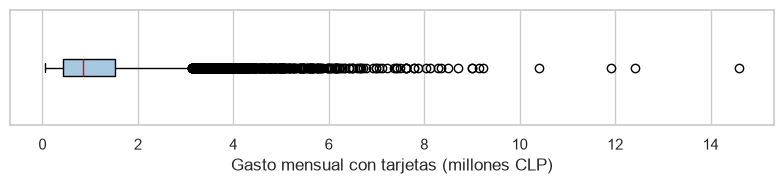

In [13]:
# Outliers en gasto_mensual_tarjetas_clp (criterio IQR)
g = caracteristicas['gasto_mensual_tarjetas_clp']
q1, q3 = g.quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
n_out = (g > lim_sup).sum()
print(f"Valores <= 0: {(g <= 0).sum()}")
print(f"Mín: {g.min():,.0f} | Máx: {g.max():,.0f} | Asimetría: {g.skew():.2f}")
print(f"Límite superior IQR: {lim_sup:,.0f} -> {n_out} outliers ({n_out/len(g)*100:.2f}%)")

fig, ax = plt.subplots(figsize=(8, 2))
ax.boxplot(g / 1_000_000, orientation='horizontal', patch_artist=True,
           boxprops=dict(facecolor='#a6c8e0'), medianprops=dict(color='red'))
ax.set_xlabel("Gasto mensual con tarjetas (millones CLP)")
ax.set_yticks([])
plt.tight_layout()
plt.show()

#### Resultados de los chequeos adicionales (comportamiento, demografía y percepción)
- **Duplicados:** 25 filas duplicadas exactas en `usuarios` (`12.025` filas para `12.000` `user_id` únicos); `0` duplicados de `user_id` en demografía y `0` pares (`user_id`, `brand`) repetidos en percepción.
- **Consistencia temporal (`age` vs. `months_active`):** además de los 15 casos con edad actual fuera de `[18, 110]`, existen 263 usuarios con edad actual válida (18 o 19 años) cuya antigüedad en meses sugiere una edad $< 18$ al momento del alta (`age - months_active/12 < 18`). A diferencia de los 15 registros fuera de rango actual, estos 263 casos se conservan sin alterar su edad porque su edad vigente cumple el requisito legal ($\ge 18$) y el desfase responde al truncamiento de la edad en años enteros o al proceso de generación sintética de los datos.
- **Consistencia de tarjetas:** `0` casos de `tiene_tarjeta_credito` contradictorios con `n_tarjetas_credito`.
- **Codificación de categorías:** sin variantes de escritura. Hay 12 bancos y 16 regiones, que corresponden exactamente a las 16 regiones de Chile.
- **Rango de percepción:** todas las notas válidas están entre 1 y 7.
- **Gasto mensual:** sin valores $\le 0$ (mínimo CLP 48.000). Por criterio IQR hay 602 outliers (5,02%), con un máximo de CLP 14.602.000. Se conservan porque corresponden a gasto real de clientes de alto valor, y esta variable no entra al clustering, solo al perfilamiento de segmentos.

### Limpieza de las bases de datos
Habiendo diagnosticado los registros duplicados, valores fuera de rango y valores faltantes, se aplica la limpieza siguiendo un orden metodológico estricto para evitar contaminar los estadísticos de imputación:
1. **Eliminar registros duplicados** en `usuarios` para asegurar unicidad por cliente (`12.000` `user_id` únicos) y recalcular el conteo exacto de nulos sobre usuarios únicos.
2. **Diagnosticar y tratar por variable tanto los valores nulos como los valores fuera de rango** (`age` fuera de 18–110 y `risk_tolerance == 0`), calculando las medianas de referencia exclusivamente sobre los registros con valores dentro del rango válido.
3. **Estandarizar el tratamiento de nulos en la tabla demográfica (`caracteristicas_copia`)** y verificar la integridad del cruce 1 a 1 con `usuarios_copia`.

In [14]:
# 1. Eliminación de datos duplicados en la base de usuarios
usuarios_copia = usuarios.drop_duplicates(subset='user_id').reset_index(drop=True)

print(f"Filas antes de desduplicar: {len(usuarios)} | Filas después de desduplicar: {len(usuarios_copia)}")
print(f"IDs únicos en usuarios_copia: {usuarios_copia['user_id'].nunique()}")

# Comparación de nulos antes (12.025 filas) vs. después de eliminar los 25 duplicados (12.000 clientes únicos)
comparacion_nulos_dedup = pd.DataFrame({
    'Nulos_brutos (12.025 filas)': usuarios.isnull().sum(),
    'Nulos_unicos (12.000 clientes)': usuarios_copia.isnull().sum(),
    'Nulos_en_filas_duplicadas': usuarios.isnull().sum() - usuarios_copia.isnull().sum()
})
display(comparacion_nulos_dedup)

Filas antes de desduplicar: 12025 | Filas después de desduplicar: 12000
IDs únicos en usuarios_copia: 12000


,Nulos_brutos (12.025 filas),Nulos_unicos (12.000 clientes),Nulos_en_filas_duplicadas
user_id,0,0,0
age,185,184,1
total_invested,0,0,0
risk_tolerance,378,377,1
months_active,0,0,0
app_sessions_month,444,442,2


In [15]:
# 2. Análisis de valores nulos y fuera de rango en la columna EDAD (age)
analisis_completo = usuarios_copia.merge(caracteristicas, on='user_id', how='left')

condiciones_edad = [
    analisis_completo['age'].isnull(),
    ~analisis_completo['age'].between(18, 110)
]
opciones_edad = ['Nulo (NaN)', 'Fuera de rango (<18 o >110)']
analisis_completo['estado_edad'] = np.select(condiciones_edad, opciones_edad, default='Válido (18-110)')

tabla_nulos_edad = (
    analisis_completo
    .groupby('estado_edad')
    .agg(
        total_usuarios=('user_id', 'count'),
        edad_promedio_valida=('age', lambda x: x[x.between(18, 110)].mean()),
        inversion_promedio=('total_invested', 'mean'),
        meses_promedio=('months_active', 'mean'),
        gasto_tarjetas_prom=('gasto_mensual_tarjetas_clp', 'mean'),
        maximo_meses=('months_active', 'max')
    )
    .assign(porcentaje=lambda x: (x['total_usuarios'] / x['total_usuarios'].sum() * 100).round(2))
)

print("----- Diagnóstico de EDAD: Válidos vs. Nulos vs. Fuera de Rango -----")
display(tabla_nulos_edad.round(2))

----- Diagnóstico de EDAD: Válidos vs. Nulos vs. Fuera de Rango -----


,total_usuarios,edad_promedio_valida,inversion_promedio,meses_promedio,gasto_tarjetas_prom,maximo_meses,porcentaje
estado_edad,,,,,,,
Fuera de rango (<18 o >110),15,NaN,"12,974,206.67",40.73,"1,608,666.67",68,0.12
Nulo (NaN),184,NaN,"17,586,988.04",51.15,"1,722,163.04",96,1.53
Válido (18-110),11801,33.61,"7,957,956.44",32.26,"1,146,234.64",96,98.34


Al analizar las anomalías en `age` sobre los 12.000 clientes únicos (tras remover 1 nulo que pertenecía a una fila duplicada), observamos dos grupos que requieren tratamiento:
1. **Valores faltantes (`184` registros, `1,53%`):** No son datos aleatorios (MCAR), sino **MAR** asociados a la antigüedad. Corresponden a clientes con una antigüedad promedio de **51,15 meses** y una inversión promedio de **CLP 17,59 millones** (más del doble que el promedio de quienes sí tienen edad válida, CLP 7,96 millones). Esto sugiere que en los primeros años de Fintual el formulario de registro permitía omitir la fecha de nacimiento.
2. **Valores fuera de rango (`15` registros, `0,12%`):** Incluyen errores de digitación (`0, 3, 7, 112, 134, 150` años) y `8` casos con `17` años. También corresponden a clientes reales con una antigüedad media de **40,73 meses** y **CLP 12,97 millones** invertidos (por ejemplo, `FTL_05443` acumula más de CLP 74 millones y 67 meses de antigüedad).

**Tratamiento aplicado (`199` registros en total):** Eliminar estos clientes sesgaría a la baja el patrimonio administrado (AUM) y rompería la relación 1 a 1 con la base demográfica (`12.000` usuarios). Por ello, calculamos la mediana de edad **exclusivamente sobre los 11.801 registros con edad válida (`18 a 110` años)** e imputamos tanto los 184 nulos como los 15 fuera de rango según su tramo de antigüedad: a quienes llevan $\ge 50$ meses se les asigna la mediana de sus pares (**43,0 años**) y a quienes llevan $< 50$ meses la mediana general (**33,0 años**).

In [16]:
# Calcular medianas exclusivamente sobre registros con edad válida (18 a 110 años)
mask_edad_valida = usuarios_copia['age'].between(18, 110)
mediana_general = usuarios_copia.loc[mask_edad_valida, 'age'].median()
mediana_50meses = usuarios_copia.loc[mask_edad_valida & (usuarios_copia['months_active'] >= 50), 'age'].median()

print(f"Mediana de edad general (sobre edades válidas 18-110): {mediana_general}")
print(f"Mediana de edad para usuarios con >= 50 meses activos (sobre edades válidas): {mediana_50meses}")

# Identificar los 184 nulos y 15 fuera de rango en usuarios_copia
mask_imputar_edad = usuarios_copia['age'].isna() | ~usuarios_copia['age'].between(18, 110)
print(f"Total registros de edad a imputar (184 nulos + 15 fuera de rango): {mask_imputar_edad.sum()}")

# Imputar según tramo de antigüedad
usuarios_copia.loc[mask_imputar_edad, 'age'] = usuarios_copia.loc[mask_imputar_edad, 'months_active'].apply(
    lambda x: mediana_50meses if x >= 50 else mediana_general
)

# Actualizar analisis_completo con la edad ya limpia para no contaminar los análisis siguientes
analisis_completo['age'] = usuarios_copia['age']

Mediana de edad general (sobre edades válidas 18-110): 33.0
Mediana de edad para usuarios con >= 50 meses activos (sobre edades válidas): 43.0
Total registros de edad a imputar (184 nulos + 15 fuera de rango): 199


In [17]:
# 3. Análisis de valores nulos y fuera de rango (= 0) en TOLERANCIA AL RIESGO (risk_tolerance)
condiciones_riesgo = [
    analisis_completo['risk_tolerance'].isnull(),
    ~analisis_completo['risk_tolerance'].between(1, 5)
]
opciones_riesgo = ['Nulo (NaN)', 'Fuera de rango (= 0)']
analisis_completo['estado_riesgo'] = np.select(condiciones_riesgo, opciones_riesgo, default='Válido (1 a 5)')

tabla_nulos_riesgo = (
    analisis_completo
    .groupby('estado_riesgo')
    .agg(
        total_usuarios=('user_id', 'count'),
        edad_promedio=('age', 'mean'),
        inversion_promedio=('total_invested', 'mean'),
        meses_promedio=('months_active', 'mean'),
        sesiones_app_prom=('app_sessions_month', 'mean'),
        gasto_tarjetas_prom=('gasto_mensual_tarjetas_clp', 'mean')
    )
    .assign(porcentaje=lambda x: (x['total_usuarios'] / x['total_usuarios'].sum() * 100).round(2))
)
print("----- Diagnóstico de TOLERANCIA AL RIESGO: Válidos (1-5) vs. Nulos vs. Cero -----")
display(tabla_nulos_riesgo.round(2))

----- Diagnóstico de TOLERANCIA AL RIESGO: Válidos (1-5) vs. Nulos vs. Cero -----


,total_usuarios,edad_promedio,inversion_promedio,meses_promedio,sesiones_app_prom,gasto_tarjetas_prom,porcentaje
estado_riesgo,,,,,,,
Fuera de rango (= 0),70,33.46,"7,579,897.14",30.73,20.78,"1,096,385.71",0.58
Nulo (NaN),377,28.85,"4,507,414.85",19.59,24.28,"797,519.89",3.14
Válido (1 a 5),11553,33.86,"8,232,716.58",32.99,20.87,"1,167,689.00",96.28


Al separar los registros con escala válida (`1 a 5`, `11.553` clientes) de las dos anomalías detectadas en `risk_tolerance` (tras descontar 1 nulo de una fila duplicada), se distinguen dos patrones claros:
1. **Valores faltantes (`377` registros con `NaN`, `3,14%`):** Presentan un patrón **MAR**. Comparados con los usuarios con riesgo válido (`1 a 5`), son más jóvenes (**28,85 años** vs. **33,86 años**), llevan menos tiempo en Fintual (**19,59 meses** vs. **32,99 meses**), invierten cerca de la mitad (**CLP 4,51M** vs. **CLP 8,23M**) y abren más la app (**24,28** vs. **20,87** sesiones/mes). Corresponden a usuarios más recientes en etapa de exploración que aún no han completado su perfilamiento.
2. **Valores codificados como `0.0` (`70` registros, `0,58%`):** Fuera de la escala oficial de `1` (muy conservador) a `5` (muy agresivo). A diferencia de los `NaN`, estos 70 usuarios tienen un perfil prácticamente idéntico al promedio general de Fintual (**33,46 años**, **30,73 meses** de antigüedad, **CLP 7,58M** invertidos y **20,78** sesiones/mes), lo que indica una codificación por defecto del sistema (`0` = sin cuestionario registrado) en cuentas de distintas cohortes.

**Tratamiento aplicado (`447` registros en total):** Se calcula la mediana de `risk_tolerance` exclusivamente sobre los `11.553` registros válidos (`mediana = 3,0`, perfil moderado/neutral) y se imputa tanto a los `377` valores nulos como a los `70` registros con valor `0.0`.

In [18]:
# Calcular mediana exclusivamente sobre registros con tolerancia al riesgo válida (1 a 5)
mask_riesgo_valido = usuarios_copia['risk_tolerance'].between(1, 5)
mediana_riesgo = usuarios_copia.loc[mask_riesgo_valido, 'risk_tolerance'].median()
print(f"Mediana de tolerancia al riesgo (sobre escala válida 1-5): {mediana_riesgo}")

# Imputar tanto los 377 nulos como los 70 registros con valor 0.0 (447 registros en total)
mask_imputar_riesgo = usuarios_copia['risk_tolerance'].isna() | ~usuarios_copia['risk_tolerance'].between(1, 5)
print(f"Total registros de riesgo a imputar (377 nulos + 70 en cero): {mask_imputar_riesgo.sum()}")

usuarios_copia.loc[mask_imputar_riesgo, 'risk_tolerance'] = mediana_riesgo
analisis_completo['risk_tolerance'] = usuarios_copia['risk_tolerance']

Mediana de tolerancia al riesgo (sobre escala válida 1-5): 3.0
Total registros de riesgo a imputar (377 nulos + 70 en cero): 447


In [19]:
# 4. Análisis de los valores nulos en SESIONES MENSUALES EN LA APP (app_sessions_month)
tabla_nulos_sesiones = (
    analisis_completo
    .assign(falta_sesiones=analisis_completo['app_sessions_month'].isnull())
    .groupby('falta_sesiones')
    .agg(
        total_usuarios=('user_id', 'count'),
        inversion_promedio=('total_invested', 'mean'),
        meses_promedio=('months_active', 'mean'),
        edad_promedio=('age', 'mean'),
        riesgo_promedio=('risk_tolerance', 'mean')
    )
    .assign(porcentaje=lambda x: (x['total_usuarios'] / x['total_usuarios'].sum() * 100).round(2))
)
print("----- Diagnóstico de Nulos en SESIONES MENSUALES APP -----")
display(tabla_nulos_sesiones.round(2))

----- Diagnóstico de Nulos en SESIONES MENSUALES APP -----


,total_usuarios,inversion_promedio,meses_promedio,edad_promedio,riesgo_promedio,porcentaje
falta_sesiones,,,,,,
False,11558,"8,129,083.30",32.60,33.73,3.23,96.32
True,442,"7,661,805.43",31.45,32.97,3.28,3.68


Al examinar los **442 valores faltantes** en `app_sessions_month` (`3,68%` de los 12.000 clientes únicos, tras descontar 2 nulos que estaban en filas duplicadas), comprobamos que presentan el mismo perfil que los usuarios con registro de sesiones: antigüedad media de **31,45 meses** (vs. **32,60**), edad promedio de **32,97 años** (vs. **33,73**), riesgo medio de **3,28** (vs. **3,23**) e inversión promedio de **CLP 7,66M** (vs. **CLP 8,13M**). Por lo tanto, la ausencia del dato es compatible con un fallo aleatorio de telemetría (**MCAR**) y se imputa con la mediana general (**21,0 sesiones/mes**).

In [20]:
# calcular la mediana de sesiones mensuales en la app
mediana_sesiones = usuarios_copia['app_sessions_month'].median()
print(f"Mediana de sesiones mensuales en la app: {mediana_sesiones}")

# rellenar los valores nulos de sesiones mensuales en la app con la mediana correspondiente
usuarios_copia['app_sessions_month'] = usuarios_copia['app_sessions_month'].fillna(mediana_sesiones)

Mediana de sesiones mensuales en la app: 21.0


#### Resumen consolidado del tratamiento en la base de comportamiento (`usuarios_copia`)

| Problema detectado | Variable afectada | Registros afectados | % sobre 12.000 únicos | Mecanismo / Causa | Tratamiento aplicado y justificación |
| :--- | :--- | :---: | :---: | :--- | :--- |
| **Filas duplicadas** | Todas (`user_id` repetido) | 25 filas | 0,21% (de 12.025) | Duplicación exacta de extracción | Eliminación (`drop_duplicates`), preservando los 12.000 clientes únicos que cruzan 1 a 1 con demografía. |
| **Valores faltantes (`NaN`)** | `age` | 184 | 1,53% | MAR (antigüedad media 51,15 meses; AUM prom. CLP 17,59M) | Imputación condicionada por antigüedad: mediana de pares $\ge 50$ meses (**43 años**) o mediana general $< 50$ meses (**33 años**). |
| **Valores fuera de rango** | `age` ($<18$ o $>110$) | 15 | 0,12% | Errores de digitación (`0, 3, 7, 17, 112, 134, 150`) en cuentas activas | Misma regla de imputación por antigüedad (**43** o **33 años**) para no perder clientes reales con alto saldo invertido. |
| **Valores faltantes (`NaN`)** | `risk_tolerance` | 377 | 3,14% | MAR (usuarios más jóvenes, 28,85 años y 19,59 meses de antigüedad) | Imputación con la mediana de la escala válida 1–5 (**3,0**, perfil moderado). |
| **Codificación inconsistente** | `risk_tolerance` ($= 0$) | 70 | 0,58% | Código `0` del sistema para cuentas no perfiladas (edad media 33,46 años) | Imputación con la mediana de la escala válida 1–5 (**3,0**, perfil moderado). |
| **Valores faltantes (`NaN`)** | `app_sessions_month` | 442 | 3,68% | MCAR (sin diferencias relevantes en edad, inversión ni antigüedad) | Imputación con la mediana general (**21,0 sesiones/mes**). |

In [21]:
# Verificación final de usuarios_copia tras limpiar duplicados, nulos y valores fuera de rango
print("Nulos restantes en usuarios_copia:", usuarios_copia.isnull().sum().sum())
print(f"Rango de edad limpia: [{usuarios_copia['age'].min():.0f}, {usuarios_copia['age'].max():.0f}]")
print(f"Rango de tolerancia al riesgo limpia: [{usuarios_copia['risk_tolerance'].min():.0f}, {usuarios_copia['risk_tolerance'].max():.0f}]")
display(usuarios_copia.describe().T)

Nulos restantes en usuarios_copia: 0
Rango de edad limpia: [18, 67]
Rango de tolerancia al riesgo limpia: [1, 5]


,count,mean,std,min,25%,50%,75%,max
age,"12,000.00",33.70,9.98,18.00,25.00,33.00,41.00,67.00
total_invested,"12,000.00","8,111,871.90","13,938,875.54","15,500.00","302,925.00","2,825,000.00","9,642,425.00","239,386,000.00"
risk_tolerance,"12,000.00",3.23,1.17,1.00,2.00,3.00,4.00,5.00
months_active,"12,000.00",32.56,22.29,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"12,000.00",20.98,9.82,1.00,13.00,21.00,29.00,47.00


In [22]:
# 5. Tratamiento de los valores nulos en la tabla demográfica (caracteristicas_copia)
caracteristicas_copia = caracteristicas.copy()

# Valores nulos en genero (228 casos, 1,90%) -> 'Sin dato'
caracteristicas_copia['genero'] = caracteristicas_copia['genero'].fillna('Sin dato')

# Valores nulos en region (119 casos, 0,99%) -> 'Sin dato' (evita inflar artificialmente la Región Metropolitana con la moda)
caracteristicas_copia['region'] = caracteristicas_copia['region'].fillna('Sin dato')

# Valores nulos en tramo_ingreso (991 casos, 8,26%) -> 'No declara'
caracteristicas_copia['tramo_ingreso'] = caracteristicas_copia['tramo_ingreso'].fillna('No declara')

# Comprobación rápida de nulos restantes (solo interes_fintual_card permanece con NaN por diseño)
print("Nulos restantes en caracteristicas_copia:")
display(caracteristicas_copia.isna().sum().to_frame(name='Nulos'))

Nulos restantes en caracteristicas_copia:


,Nulos
user_id,0
region,0
genero,0
tramo_ingreso,0
ocupacion,0
banco_principal,0
tiene_tarjeta_credito,0
n_tarjetas_credito,0
billetera_digital_principal,0
gasto_mensual_tarjetas_clp,0


En la tabla demográfica (`caracteristicas_copia`) aplicamos un criterio diferenciado según la naturaleza de cada variable:
1. **`genero` (228 nulos, 1,90%) y `region` (119 nulos, 0,99%):** Corresponden a omisiones aleatorias en el formulario (**MCAR**). En ambos casos se asigna la categoría explícita `'Sin dato'` en lugar de imputar con la moda, ya que asignar la moda en `region` agregaría artificialmente 119 clientes a la *Región Metropolitana de Santiago*, distorsionando la distribución geográfica real.
2. **`tramo_ingreso` (991 nulos, 8,26%):** Se trata como **MNAR** (*Missing Not At Random*), dado que en Chile el ingreso líquido es un dato sensible que parte de los usuarios prefiere reservarse; por ello se codifica explícitamente como `'No declara'`.
3. **`interes_fintual_card` (3.393 nulos, 28,28%):** Se mantiene **sin imputar (`NaN`)**, porque rellenar inventaría una intención de compra que el cliente no expresó en la encuesta *in-app*. Como demostramos en la celda siguiente, la tasa de no respuesta es uniforme entre grupos (~27,6% a 29,3%, compatible con **MCAR**), por lo que la ausencia de respuesta **no equivale a desinterés** y las métricas de interés se calculan sobre quienes efectivamente respondieron.

In [23]:
# ¿Los nulos de interes_fintual_card se concentran en algún tipo de usuario?
base_int = usuarios_copia.merge(caracteristicas_copia, on='user_id', how='left')
base_int['sin_respuesta_interes'] = base_int['interes_fintual_card'].isna()
base_int['tramo_edad_int'] = pd.cut(base_int['age'], bins=[17, 25, 35, 50, 100], labels=['18-25', '26-35', '36-50', '50+'])
print(f"Tasa global de no respuesta en interes_fintual_card: {base_int['sin_respuesta_interes'].mean()*100:.1f}%")
for col in ['billetera_digital_principal', 'tramo_edad_int', 'tiene_tarjeta_credito']:
    print(f"\n% sin respuesta por {col}:")
    print((base_int.groupby(col, observed=True)['sin_respuesta_interes'].mean() * 100).round(1).to_string())
print("\nPerfil medio según responda o no:")
display(base_int.groupby('sin_respuesta_interes')[['age', 'total_invested', 'gasto_mensual_tarjetas_clp']].mean().round(1))

Tasa global de no respuesta en interes_fintual_card: 28.3%

% sin respuesta por billetera_digital_principal:
billetera_digital_principal
MACH           29.00
Mercado Pago   27.60
Ninguna        28.60
Otra           27.90
Tenpo          28.40

% sin respuesta por tramo_edad_int:
tramo_edad_int
18-25   27.60
26-35   28.50
36-50   28.40
50+     29.30

% sin respuesta por tiene_tarjeta_credito:
tiene_tarjeta_credito
No   28.00
Sí   28.40

Perfil medio según responda o no:


,age,total_invested,gasto_mensual_tarjetas_clp
sin_respuesta_interes,,,
False,33.70,"8,109,277.00","1,152,865.20"
True,33.80,"8,118,454.30","1,162,691.40"


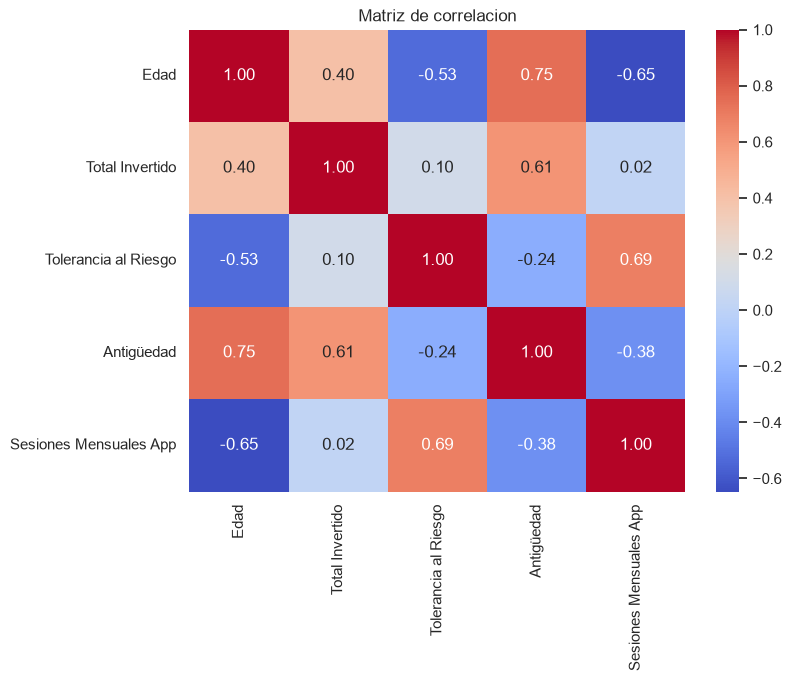

In [24]:
# Matriz de correlacion de los usuarios de fintual
variables = ['age','total_invested','risk_tolerance','months_active','app_sessions_month']

df_corr = usuarios_copia[variables].rename(columns={    'age': 'Edad',
    'total_invested': 'Total Invertido',
    'risk_tolerance': 'Tolerancia al Riesgo',
    'months_active': 'Antigüedad',
    'app_sessions_month': 'Sesiones Mensuales App'
})

matriz_corr = df_corr.corr()

# Graficar la matriz
plt.figure(figsize= (8,6))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlacion")
plt.show()

#### Interpretación de la matriz de correlación (con dirección y sentido de negocio)
- **Edad y Antigüedad ($r = +0,75$, positiva fuerte):** A mayor edad del cliente, mayor es el número de meses que lleva invirtiendo en Fintual, reflejando las cohortes históricas de adopción.
- **Tolerancia al Riesgo y Sesiones Mensuales en App ($r = +0,69$, positiva fuerte):** Los usuarios con perfiles de inversión más agresivos monitorean sus fondos con mucha mayor frecuencia mensual que los conservadores.
- **Edad y Sesiones Mensuales en App ($r = -0,65$, negativa moderada-fuerte):** Los clientes más jóvenes presentan una interacción digital mucho más intensa con la aplicación, mientras que los de mayor edad exhiben un uso pasivo o esporádico.
- **Edad y Tolerancia al Riesgo ($r = -0,53$, negativa moderada):** A medida que aumenta la edad, disminuye la tolerancia al riesgo (preferencia por preservación de capital).
- **Total Invertido con Antigüedad ($r = +0,40$) y con Edad ($r = +0,30$):** Correlaciones positivas moderadas en escala lineal, atenuadas por la fuerte asimetría positiva del patrimonio (`total_invested`), lo que refuerza la necesidad de evaluar una transformación logarítmica antes de segmentar.

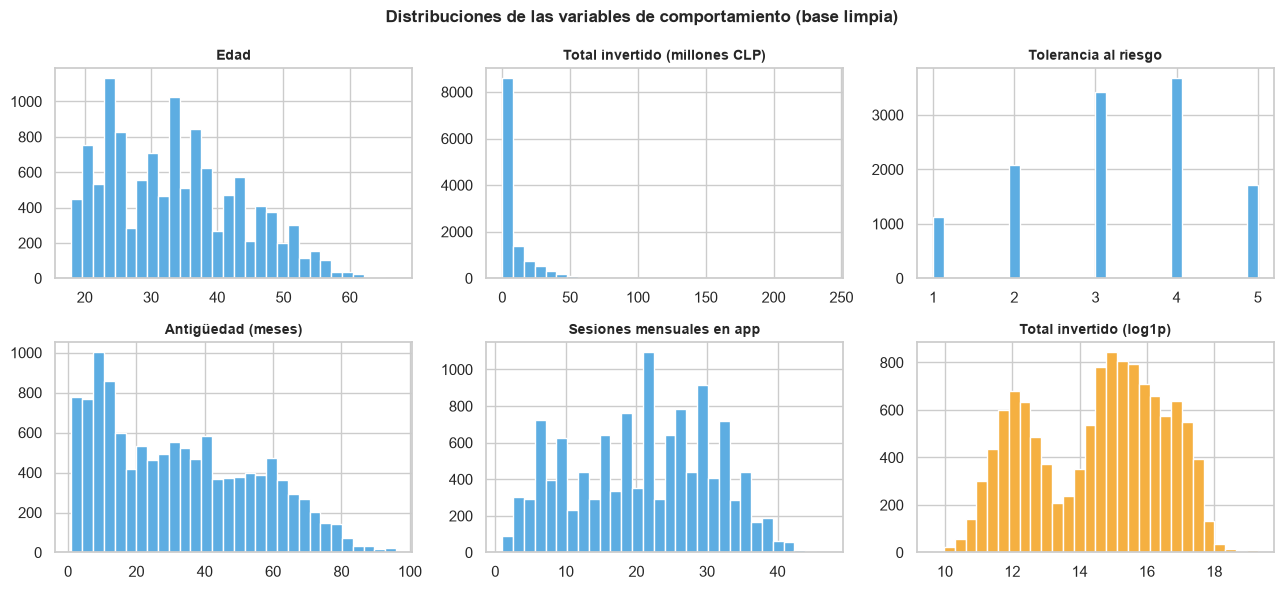

,variable,asimetria,n_outliers_IQR,pct_outliers
0,age,0.45,2,0.02
1,total_invested,5.13,1273,10.61
2,risk_tolerance,-0.27,0,0.00
3,months_active,0.44,0,0.00
4,app_sessions_month,-0.08,0,0.00


In [25]:
# Distribuciones de las 5 variables de comportamiento (+ total_invested en log)
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
etiquetas = {'age': 'Edad', 'total_invested': 'Total invertido (millones CLP)', 'risk_tolerance': 'Tolerancia al riesgo',
             'months_active': 'Antigüedad (meses)', 'app_sessions_month': 'Sesiones mensuales en app'}
for ax, var in zip(axes.flatten(), etiquetas):
    datos = usuarios_copia[var] / 1_000_000 if var == 'total_invested' else usuarios_copia[var]
    ax.hist(datos, bins=30, color='#5dade2', edgecolor='white')
    ax.set_title(etiquetas[var], fontsize=10, fontweight='bold')
axes.flatten()[5].hist(np.log1p(usuarios_copia['total_invested']), bins=30, color='#f5b041', edgecolor='white')
axes.flatten()[5].set_title('Total invertido (log1p)', fontsize=10, fontweight='bold')
plt.suptitle('Distribuciones de las variables de comportamiento (base limpia)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Asimetria y outliers por criterio IQR
vars_eda = list(etiquetas)
tabla_out = []
for v in vars_eda:
    q1, q3 = usuarios_copia[v].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_o = ((usuarios_copia[v] < q1 - 1.5 * iqr) | (usuarios_copia[v] > q3 + 1.5 * iqr)).sum()
    tabla_out.append((v, usuarios_copia[v].skew(), n_o, n_o / len(usuarios_copia) * 100))
tabla_out = pd.DataFrame(tabla_out, columns=['variable', 'asimetria', 'n_outliers_IQR', 'pct_outliers'])
display(tabla_out.round(2))

#### Distribuciones y outliers de las 5 variables
`total_invested` es la variable con mayor asimetría (skew 5,13) y concentra 1.273 outliers por criterio IQR (10,6%); con `log1p` la distribución se vuelve aproximadamente simétrica. Las demás variables tienen asimetrías entre -0,27 y 0,45 y entre 0 y 2 outliers IQR (`age`: 2). Implicancia de marketing: el promedio de inversión engaña porque una minoría de clientes muy grandes lo sube, por eso las decisiones de segmentación usan la transformación log y las descripciones usan la mediana.

#### Comparación visual de `total_invested`: escala original (CLP) vs. transformación logarítmica (`log1p`)

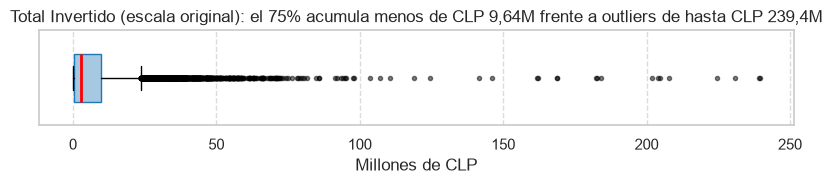

In [26]:
# Boxplot de total_invested en millones de CLP para visualizar el impacto de la cola derecha
inversion_millones = usuarios_copia['total_invested'] / 1_000_000

plt.figure(figsize=(8, 2))
plt.boxplot(
    inversion_millones, 
    orientation='horizontal',
    widths=0.5,
    patch_artist=True,
    boxprops=dict(facecolor='#a6c8e0', color='#1f77b4'),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(marker='o', markersize=3, alpha=0.5, markerfacecolor='black')
)
plt.title("Total Invertido (escala original): el 75% acumula menos de CLP 9,64M frente a outliers de hasta CLP 239,4M")
plt.xlabel("Millones de CLP")
plt.yticks([])
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

El boxplot en escala original confirma que los 1.273 outliers superiores (clientes con más de CLP 23,6 millones invertidos, llegando hasta CLP 239,4 millones) comprimen al 75% de la cartera en el extremo izquierdo del gráfico. Como estos clientes representan el núcleo del patrimonio administrado (AUM) de Fintual, **no deben eliminarse**; sin embargo, ingresar `total_invested` en bruto a un algoritmo basado en distancias euclidianas (como Ward o K-Means) haría que la cola extrema domine la partición. A continuación se verifica cómo `np.log1p(total_invested)` estabiliza la varianza y elimina los outliers estadísticos.

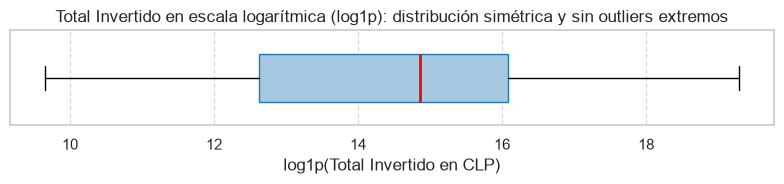

,count,mean,std,min,25%,50%,75%,max
age,"12,000.00",33.70,9.98,18.00,25.00,33.00,41.00,67.00
total_invested,"12,000.00","8,111,871.90","13,938,875.54","15,500.00","302,925.00","2,825,000.00","9,642,425.00","239,386,000.00"
risk_tolerance,"12,000.00",3.23,1.17,1.00,2.00,3.00,4.00,5.00
months_active,"12,000.00",32.56,22.29,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"12,000.00",20.98,9.82,1.00,13.00,21.00,29.00,47.00
total_invested_log1p,"12,000.00",14.51,1.97,9.65,12.62,14.85,16.08,19.29


In [27]:
# Boxplot de total_invested tras aplicar transformación logarítmica (np.log1p)
total_inv_log_serie = np.log1p(usuarios_copia['total_invested'])

plt.figure(figsize=(8, 2))
plt.boxplot(
    total_inv_log_serie, 
    orientation='horizontal',
    widths=0.5,
    patch_artist=True,
    boxprops=dict(facecolor='#a6c8e0', color='#1f77b4'),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(marker='o', markersize=3, alpha=0.5, markerfacecolor='black')
)
plt.title("Total Invertido en escala logarítmica (log1p): distribución simétrica y sin outliers extremos")
plt.xlabel("log1p(Total Invertido en CLP)")
plt.yticks([])
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Resumen estadístico comparativo de las 5 variables limpias + referencia en log1p
resumen_pre_esc = usuarios_copia[['age', 'total_invested', 'risk_tolerance', 'months_active', 'app_sessions_month']].copy()
resumen_pre_esc['total_invested_log1p'] = total_inv_log_serie
display(resumen_pre_esc.describe().T)

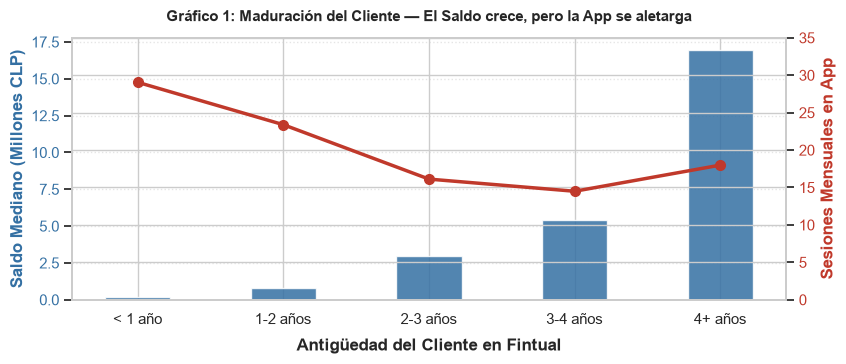

In [28]:
# GRAFICO 1: Matplotlib puro - Curva de maduracion del cliente
usuarios_copia['anios_activo'] = pd.cut(
    usuarios_copia['months_active'], 
    bins=[0, 12, 24, 36, 48, 100], 
    labels=['< 1 año', '1-2 años', '2-3 años', '3-4 años', '4+ años']
)

maduracion = usuarios_copia.groupby('anios_activo', observed=False).agg(
    saldo_mediano=('total_invested', lambda x: x.median() / 1_000_000),
    sesiones_prom=('app_sessions_month', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(8.5, 3.8))

# 1. Barras: Saldo mediano acumulado
color_barras = '#3470a3'
ax1.bar(maduracion['anios_activo'], maduracion['saldo_mediano'], color=color_barras, width=0.45, alpha=0.85)
ax1.set_xlabel("Antigüedad del Cliente en Fintual", fontweight='bold', labelpad=8)
ax1.set_ylabel("Saldo Mediano (Millones CLP)", color=color_barras, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_barras)
ax1.grid(axis='y', linestyle=':', alpha=0.5)

# 2. Linea: Frecuencia de uso de la App
ax2 = ax1.twinx()
color_linea = '#c0392b'
ax2.plot(maduracion['anios_activo'], maduracion['sesiones_prom'], color=color_linea, marker='o', linewidth=2.5, markersize=7)
ax2.set_ylabel("Sesiones Mensuales en App", color=color_linea, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_linea)
ax2.set_ylim(0, 35)

plt.title("Gráfico 1: Maduración del Cliente — El Saldo crece, pero la App se aletarga", 
          fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

Grafico 1: A medida que aumenta la antigüedad del cliente, el saldo mediano crece de forma sostenida (de 0,19 M en el primer año a 16,9 M con más de 4 años), mientras que la frecuencia de uso de la app cae de 29,1 sesiones mensuales en el primer año a 14,5 en el tramo de 3 a 4 años y repunta levemente a 18,0 en el de 4+ años. Es decir, la caída no es estrictamente progresiva. Este comportamiento admite dos hipótesis:
- Mayor confianza en el producto y maduración: El usuario entiende la idea de inversión a largo plazo y confía en la gestión.
- Pérdida de interés por la aplicación: El usuario solamente ingresa cuando quiere hacer algún tipo de transacción.
Ninguna de las dos se puede probar con estos datos; sirven como hipótesis a validar en las entrevistas.

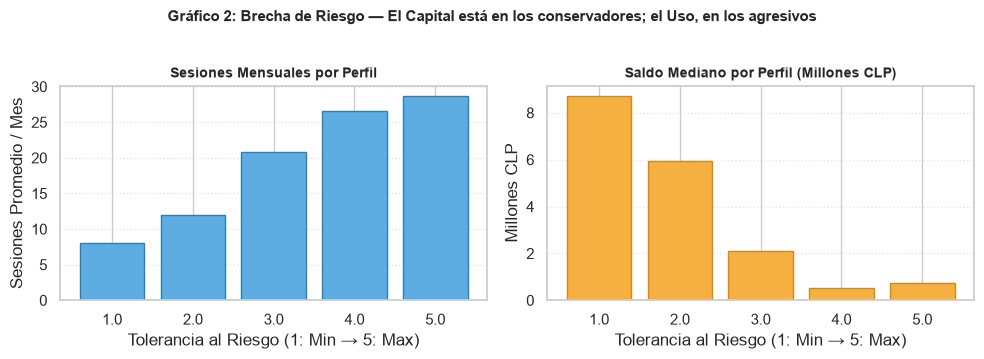

In [29]:
# GRAFICO 2: Matplotlib puro - Engagement y Saldo por Nivel de Riesgo
riesgo = usuarios_copia.groupby('risk_tolerance').agg(
    sesiones_prom=('app_sessions_month', 'mean'),
    saldo_mediano=('total_invested', lambda x: x.median() / 1_000_000)
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

# Subplot 1: Sesiones mensuales
ax1.bar(riesgo['risk_tolerance'].astype(str), riesgo['sesiones_prom'], color='#5dade2', edgecolor='#2980b9')
ax1.set_title("Sesiones Mensuales por Perfil", fontsize=10, fontweight='bold')
ax1.set_xlabel("Tolerancia al Riesgo (1: Min → 5: Max)")
ax1.set_ylabel("Sesiones Promedio / Mes")
ax1.grid(axis='y', linestyle=':', alpha=0.5)

# Subplot 2: Saldo mediano
ax2.bar(riesgo['risk_tolerance'].astype(str), riesgo['saldo_mediano'], color='#f5b041', edgecolor='#d68910')
ax2.set_title("Saldo Mediano por Perfil (Millones CLP)", fontsize=10, fontweight='bold')
ax2.set_xlabel("Tolerancia al Riesgo (1: Min → 5: Max)")
ax2.set_ylabel("Millones CLP")
ax2.grid(axis='y', linestyle=':', alpha=0.5)

plt.suptitle("Gráfico 2: Brecha de Riesgo — El Capital está en los conservadores; el Uso, en los agresivos", 
             fontsize=11, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Grafico 2: Este grafico evidencia una relación inversa entre patrimonio y frecuencia de uso: mientras los usuarios conservadores concentran el grueso del capital en Fintual con una interacción esporádica, los clientes con perfiles arriesgados son los más activos digitalmente en la app, a pesar de mantener saldos considerablemente menores.

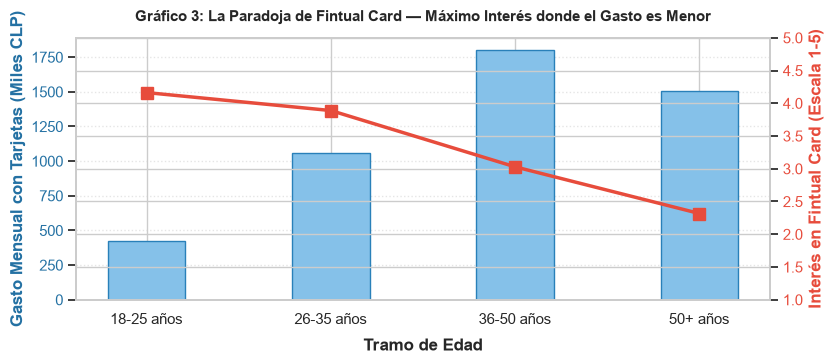

In [30]:
# GRAFICO 3: Matplotlib puro - Paradoja de Fintual Card
df_completo = usuarios_copia.merge(caracteristicas_copia, on='user_id', how='left')

df_completo['tramo_edad'] = pd.cut(
    df_completo['age'], 
    bins=[17, 25, 35, 50, 100], 
    labels=['18-25 años', '26-35 años', '36-50 años', '50+ años']
)

paradoja = df_completo.groupby('tramo_edad', observed=False).agg(
    gasto_k=('gasto_mensual_tarjetas_clp', lambda x: x.mean() / 1_000),
    interes_prom=('interes_fintual_card', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(8.5, 3.8))

# 1. Barras: Gasto mensual con tarjetas
color_gasto = '#85c1e9'
ax1.bar(paradoja['tramo_edad'], paradoja['gasto_k'], color=color_gasto, edgecolor='#2980b9', width=0.42)
ax1.set_xlabel("Tramo de Edad", fontweight='bold', labelpad=8)
ax1.set_ylabel("Gasto Mensual con Tarjetas (Miles CLP)", color='#2471a3', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#2471a3')
ax1.grid(axis='y', linestyle=':', alpha=0.5)

# 2. Linea: Interes declarado
ax2 = ax1.twinx()
color_interes = '#e74c3c'
ax2.plot(paradoja['tramo_edad'], paradoja['interes_prom'], color=color_interes, marker='s', linewidth=2.5, markersize=8)
ax2.set_ylabel("Interés en Fintual Card (Escala 1-5)", color=color_interes, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_interes)
ax2.set_ylim(1, 5)

plt.title("Gráfico 3: La Paradoja de Fintual Card — Máximo Interés donde el Gasto es Menor", 
          fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

Grafico 3: El interés declarado en Fintual Card decrece con la edad: es máximo en el tramo 18-25 años (4,16) y mínimo en el tramo 50+ años (2,32). El gasto mensual con tarjetas, en cambio, es máximo en el tramo 36-50 años (CLP 1.800 mil), y en el tramo más joven es de solo CLP 420 mil. Es el dilema central: quienes más quieren la tarjeta son quienes menos gastan, y quienes más gastan muestran un interés intermedio. Una estrategia masiva en cualquiera de los extremos sería ineficiente, lo que justifica buscar un segmento intermedio que combine intención y capacidad de gasto.

In [31]:
vars_clustering = ['age', 'total_invested', 'risk_tolerance', 'months_active', 'app_sessions_month']
# Matriz 1: Escala original estandarizada
scaler_orig = StandardScaler()
X_scaled_orig = scaler_orig.fit_transform(usuarios_copia[vars_clustering])
# Matriz 2: Con transformacion logaritmica en total_invested (para comparar en 2.3)
usuarios_log = usuarios_copia[vars_clustering].copy()
usuarios_log['total_invested'] = np.log1p(usuarios_log['total_invested'])
scaler_log = StandardScaler()
X_scaled_log = scaler_log.fit_transform(usuarios_log)
print("Matrices estandarizadas listas:")
print("1. X_scaled_orig (escala bruta):", X_scaled_orig.shape)
print("2. X_scaled_log  (con log1p):    ", X_scaled_log.shape)

Matrices estandarizadas listas:
1. X_scaled_orig (escala bruta): (12000, 5)
2. X_scaled_log  (con log1p):     (12000, 5)


# Clustering Jerarquico

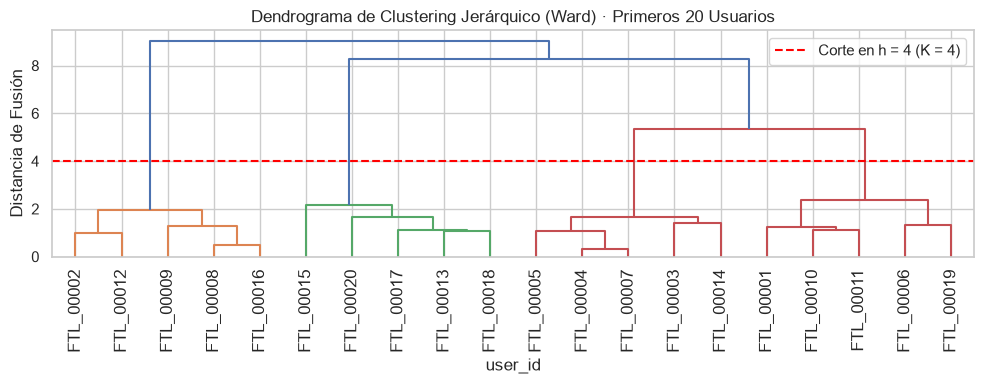

Últimas distancias de fusión: [1.96 2.15 2.36 5.36 8.27 9.02]


In [32]:
# Construccion del dendograma

# 1. Tomamos los primeros 20 usuarios estandarizados
X_20 = X_scaled_log[:20]
user_ids_20 = usuarios_copia['user_id'].iloc[:20].tolist()

# 2. Matriz de enlace Ward y dendrograma
L = linkage(X_20, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(L, labels=user_ids_20, leaf_rotation=90)
plt.axhline(y=4, color="red", linestyle="--", label="Corte en h = 4 (K = 4)")

plt.title("Dendrograma de Clustering Jerárquico (Ward) · Primeros 20 Usuarios")
plt.ylabel("Distancia de Fusión")
plt.xlabel("user_id")
plt.legend()
plt.tight_layout()
plt.show()

print("Últimas distancias de fusión:", L[-6:, 2].round(2))

La eleccion del corte en h = 4 se fundamenta en que alli se produce el mayor salto entre distancias de fusion (de 2,36 a 5,36). En otras palabras, un salto abrupto en la distancia indica que se esta forzando la union entre grupos con baja similutud y alta heterogeniedad. por lo tanto, es conveniente cortar justo ante de ese salto.

Con ese corte quedan 4 clusters, asignados en la tabla de abajo. El salto de 2,36 a 5,36 es el mayor en términos relativos (+127%), frente a +54% y +9% de los saltos siguientes; cortar más arriba (K=3 o K=2) obligaría a fusionar grupos ya muy distantes. Esto es coherente con el K=4 que eligen el método del codo y el silhouette en K-Means. El dendrograma usa las variables estandarizadas con `total_invested` en log.

In [33]:
# Asignacion de cada uno de los 20 usuarios a su cluster (corte en h = 4)
from scipy.cluster.hierarchy import fcluster
asignacion = pd.DataFrame({'user_id': user_ids_20,
                           'cluster_jerarquico': fcluster(L, t=4, criterion='distance')})
display(asignacion.sort_values(['cluster_jerarquico', 'user_id']).reset_index(drop=True))
print("Usuarios por cluster:")
print(asignacion['cluster_jerarquico'].value_counts().sort_index().to_string())
print("Número de clusters:", asignacion['cluster_jerarquico'].nunique())
print("Saltos relativos entre fusiones finales:", (L[-5:, 2] / L[-6:-1, 2] - 1).round(2))

,user_id,cluster_jerarquico
0,FTL_00002,1
1,FTL_00008,1
2,FTL_00009,1
3,FTL_00012,1
4,FTL_00016,1
5,FTL_00013,2
6,FTL_00015,2
7,FTL_00017,2
8,FTL_00018,2
9,FTL_00020,2


Usuarios por cluster:
cluster_jerarquico
1    5
2    5
3    5
4    5
Número de clusters: 4
Saltos relativos entre fusiones finales: [0.09 0.1  1.27 0.54 0.09]


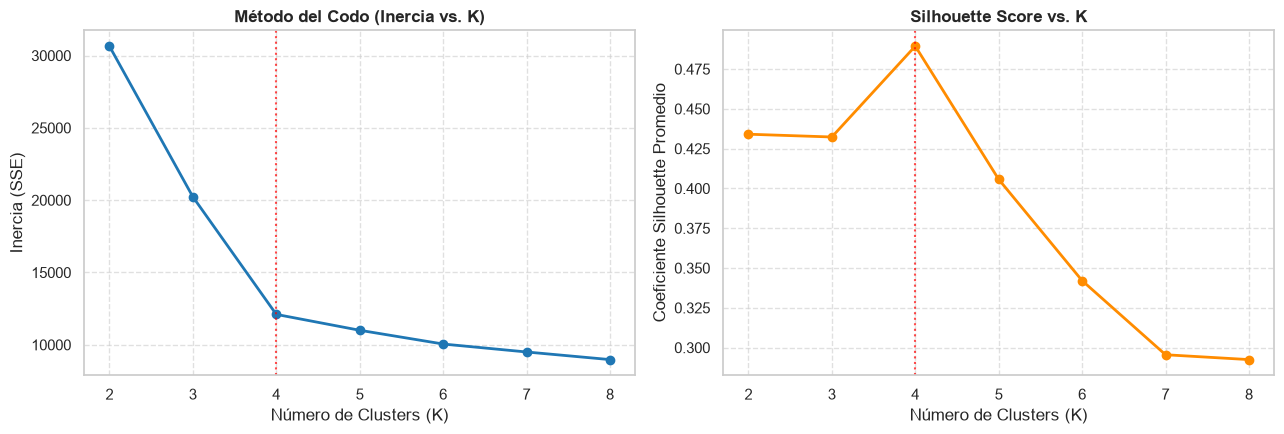

In [34]:
# Metodo K-means

resultados_k = []

for k in range(2,9):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled_log) # Inercia y Silhouette score 
    silhouette = silhouette_score(X_scaled_log, km. labels_)
    resultados_k.append((k, km.inertia_, silhouette))

# Ver dataframe resumen
resumen_kmeans = pd.DataFrame(resultados_k, columns=["K","inercia", "silhouette"])
resumen_kmeans

# Graficos configuracion
fig, ax = plt.subplots(1,2, figsize =(13, 4.5))

# Gráfico del Codo
ax[0].plot(resumen_kmeans.K, resumen_kmeans.inercia, "o-", color="tab:blue", linewidth=2)
ax[0].set_title("Método del Codo (Inercia vs. K)", fontsize=12, weight='bold')
ax[0].set_xlabel("Número de Clusters (K)")
ax[0].set_ylabel("Inercia (SSE)")
ax[0].grid(True, linestyle="--", alpha=0.6)
# Gráfico de Silhouette
ax[1].plot(resumen_kmeans.K, resumen_kmeans.silhouette, "o-", color="darkorange", linewidth=2)
ax[1].set_title("Silhouette Score vs. K", fontsize=12, weight='bold')
ax[1].set_xlabel("Número de Clusters (K)")
ax[1].set_ylabel("Coeficiente Silhouette Promedio")
ax[1].grid(True, linestyle="--", alpha=0.6)

# Resaltar K=4 en ambos gráficos
ax[0].axvline(4, color="red", linestyle=":", alpha=0.7)
ax[1].axvline(4, color="red", linestyle=":", alpha=0.7)

plt.tight_layout()
plt.show()


In [35]:
# 4. Tabla de resultados numéricos
print("Resultados de Evaluación de Clusters:")
display(resumen_kmeans.round(3))

Resultados de Evaluación de Clusters:


,K,inercia,silhouette
0,2,"30,651.02",0.43
1,3,"20,233.89",0.43
2,4,"12,102.81",0.49
3,5,"11,005.14",0.41
4,6,"10,054.24",0.34
5,7,"9,504.09",0.30
6,8,"8,977.18",0.29


Al evaluar las distintas cantidades de clústeres con el método del codo y el silhouette, **K=4 es la mejor elección en la versión con log**: maximiza el silhouette (0,489) y es donde la caída de inercia se frena (−8.131 entre K=3 y K=4, contra −1.098 entre K=4 y K=5). La comparación con la versión sin log está más abajo.

In [36]:
# 2. Función para correr K-Means según especificación obligatoria
def correr_kmeans(k, Zm=X_scaled_log):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(Zm)
    return km, km.labels_

km3, usuarios_copia["k3"] = correr_kmeans(3)
km4, usuarios_copia["k4"] = correr_kmeans(4)

# 3. Función para reportar los centroides matemáticos des-estandarizados (con expm1 en total_invested = media geométrica)
def centroides_originales(km):
    c = pd.DataFrame(scaler_log.inverse_transform(km.cluster_centers_), columns=vars_clustering)
    c['total_invested'] = np.expm1(c['total_invested'])
    c["n"] = np.bincount(km.labels_)
    return c.round(1)

print(f"K=3 · Inercia={km3.inertia_:,.0f} · Silhouette={silhouette_score(X_scaled_log, usuarios_copia.k3):.3f} (Centroides des-estandarizados; total_invested = media geométrica)")
display(centroides_originales(km3))
print(f"K=4 · Inercia={km4.inertia_:,.0f} · Silhouette={silhouette_score(X_scaled_log, usuarios_copia.k4):.3f} (Centroides des-estandarizados; total_invested = media geométrica)")
display(centroides_originales(km4))

K=3 · Inercia=20,234 · Silhouette=0.432 (Centroides des-estandarizados; total_invested = media geométrica)


,age,total_invested,risk_tolerance,months_active,app_sessions_month,n
0,35.10,"6,000,320.80",3.50,41.10,21.00,5357
1,23.10,"184,819.60",3.90,9.20,29.50,4049
2,47.40,"8,644,416.90",1.70,51.40,7.60,2594


K=4 · Inercia=12,103 · Silhouette=0.489 (Centroides des-estandarizados; total_invested = media geométrica)


,age,total_invested,risk_tolerance,months_active,app_sessions_month,n
0,39.20,"28,125,875.00",4.40,64.00,28.60,1761
1,23.10,"183,439.00",3.90,9.10,29.50,4027
2,47.90,"8,977,646.80",1.70,52.30,7.40,2483
3,33.10,"2,816,240.70",3.00,29.90,17.10,3729


In [37]:
# Media aritmética y mediana por cluster directamente en escala original (CLP)
df_analisis = usuarios_copia[['age', 'total_invested', 'risk_tolerance', 'months_active', 'app_sessions_month']].copy()
df_analisis['cluster_k3'] = km3.labels_
df_analisis['cluster_k4'] = km4.labels_

print("--- Estadísticos por Cluster K=3 en Escala Original CLP (Media Aritmética y Mediana) ---")
display(df_analisis.groupby('cluster_k3').agg({
    'age': 'mean',
    'total_invested': ['mean', 'median'],
    'risk_tolerance': 'mean',
    'months_active': 'mean',
    'app_sessions_month': 'mean',
    'cluster_k3': 'count'
}).round(1))

print("\n--- Estadísticos por Cluster K=4 en Escala Original CLP (Media Aritmética y Mediana) ---")
display(df_analisis.groupby('cluster_k4').agg({
    'age': 'mean',
    'total_invested': ['mean', 'median'],
    'risk_tolerance': 'mean',
    'months_active': 'mean',
    'app_sessions_month': 'mean',
    'cluster_k4': 'count'
}).round(1))

--- Estadísticos por Cluster K=3 en Escala Original CLP (Media Aritmética y Mediana) ---


age total_invested              risk_tolerance months_active app_sessions_month cluster_k3
            mean           mean       median           mean          mean               mean      count
cluster_k3                                                                                             
0          35.10  12,904,909.80 4,203,700.00           3.50         41.10              21.00       5357
1          23.10     249,368.70   181,300.00           3.90          9.20              29.50       4049
2          47.40  10,486,186.20 8,882,150.00           1.70         51.40               7.60       2594


--- Estadísticos por Cluster K=4 en Escala Original CLP (Media Aritmética y Mediana) ---


age total_invested               risk_tolerance months_active app_sessions_month cluster_k4
            mean           mean        median           mean          mean               mean      count
cluster_k4                                                                                              
0          39.20  32,176,411.90 27,699,000.00           4.40         64.00              28.60       1761
1          23.10     246,126.70    180,700.00           3.90          9.10              29.50       4027
2          47.90  10,729,297.80  9,112,700.00           1.70         52.30               7.40       2483
3          33.10   3,499,008.60  2,774,100.00           3.00         29.90              17.10       3729

In [38]:
# Comparacion de K-Means CON y SIN transformacion logaritmica de total_invested
from sklearn.metrics import adjusted_rand_score
res_orig = []
for k in range(2, 9):
    km_o = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X_scaled_orig)
    res_orig.append((k, km_o.inertia_, silhouette_score(X_scaled_orig, km_o.labels_)))
comparacion = resumen_kmeans.rename(columns={'inercia': 'inercia_log', 'silhouette': 'silhouette_log'}).merge(
    pd.DataFrame(res_orig, columns=['K', 'inercia_sin_log', 'silhouette_sin_log']), on='K')
print(comparacion.to_string(index=False, float_format=lambda x: f"{x:,.3f}"))

km3_o = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42).fit(X_scaled_orig)
km4_o = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42).fit(X_scaled_orig)
ari3 = adjusted_rand_score(km3.labels_, km3_o.labels_)
ari4 = adjusted_rand_score(km4.labels_, km4_o.labels_)
print(f"\nConcordancia (ARI) entre segmentaciones con y sin log -> K=3: {ari3:.3f} | K=4: {ari4:.3f}")

# Que segmento aparece/desaparece al pasar de K=3 a K=4
print("\nTransito de clusters K=3 (filas) -> K=4 (columnas):")
print(pd.crosstab(usuarios_copia['k3'], usuarios_copia['k4']).to_string())

 K  inercia_log  silhouette_log  inercia_sin_log  silhouette_sin_log
 2   30,651.020           0.434       37,060.935               0.380
 3   20,233.889           0.432       23,245.002               0.450
 4   12,102.814           0.489       15,661.609               0.449
 5   11,005.137           0.406       13,383.164               0.455
 6   10,054.237           0.342       12,300.562               0.390
 7    9,504.086           0.296       11,177.829               0.368
 8    8,977.176           0.292       10,230.014               0.328

Concordancia (ARI) entre segmentaciones con y sin log -> K=3: 0.358 | K=4: 0.981

Transito de clusters K=3 (filas) -> K=4 (columnas):
k4     0     1     2     3
k3                        
0   1759     0     2  3596
1      0  4027     0    22
2      2     0  2481   111


#### Comparación K=3 vs K=4 (criterio de negocio) y efecto de la transformación logarítmica

**De K=3 a K=4 aparece un segmento.** Los clusters de jóvenes y de conservadores se mantienen casi idénticos (ver tabla de tránsito). El cluster intermedio de K=3 (5.357 usuarios, perfil mixto) se divide en dos: **Millennials en Crecimiento** (3.596 usuarios) e **Inversionistas Wealth** (1.759 usuarios). Inversionistas Wealth es el segmento que K=3 esconde: 14,7% de los usuarios concentra 58,2% del AUM, con riesgo promedio alto y uso intensivo de la app. Para el negocio, K=4 es mejor porque separa a quienes tienen el capital de quienes tienen el volumen de usuarios, y esa distinción es la que importa para decidir a quién dirigir Fintual Card.

**Soporte estadístico.** Silhouette K=3 = 0,432 vs K=4 = 0,489, y la inercia baja de 20.234 a 12.103 (−8.131), mientras que de K=4 a K=5 baja solo 1.098. El codo está en K=4.

**¿Cambian las conclusiones sin log en `total_invested`?** Con K=4 los segmentos son prácticamente los mismos (concordancia ARI = 0,981), por lo que el perfilamiento final es robusto a la transformación. Con K=3, en cambio, la partición cambia bastante (ARI = 0,358), probablemente porque sin log los saldos extremos dominan la distancia. Además, la selección de K es sensible: sin log el silhouette es 0,450 para K=3, 0,449 para K=4 y 0,455 para K=5 (máximo en K=5), es decir, K=4 deja de destacar. Con log, K=4 es el máximo claro (0,489). Por eso usamos la versión con log: reduce el peso de los 1.273 outliers de inversión y entrega una partición más definida, sin alterar los segmentos finales de K=4. (Las inercias con y sin log no son comparables entre sí.)

**Nota sobre los centroides.** Los centroides de la primera tabla se obtienen invirtiendo el escalado y el log, por lo que `total_invested` es una **media geométrica** (más cercana a la mediana). La segunda tabla muestra la media aritmética y la mediana de cada cluster. Para describir al segmento típico usamos la **mediana**, que es robusta a los outliers.

In [39]:
# Perfilamiento accionable

# 1. Aseguramos el cluster K=4 en usuarios_copia y unimos con caracteristicas_copia (base demográfica limpia)
usuarios_copia['cluster'] = km4.labels_
df_completo = usuarios_copia.merge(caracteristicas_copia, on='user_id', how='left')

# 2. Construcción de la Tabla Maestra de Segmentos
resumen_segmentos = df_completo.groupby('cluster').agg(
    n_usuarios=('user_id', 'count'),
    edad_prom=('age', 'mean'),
    antiguedad_meses=('months_active', 'mean'),
    sesiones_mes=('app_sessions_month', 'mean'),
    riesgo_prom=('risk_tolerance', 'mean'),
    saldo_prom_clp=('total_invested', 'mean'),
    saldo_mediana_clp=('total_invested', 'median'),
    aum_total_m_clp=('total_invested', lambda x: x.sum() / 1_000_000), # Millones de pesos
    gasto_tarjetas_prom=('gasto_mensual_tarjetas_clp', 'mean'),
    pct_con_tarjeta_credito=('tiene_tarjeta_credito', lambda x: (x == 'Sí').mean() * 100),
    banco_principal=('banco_principal', lambda x: x.mode()[0]),
    billetera_top=('billetera_digital_principal', lambda x: x.mode()[0]),
    region_top=('region', lambda x: x.mode()[0] if not x.mode().empty else 'N/A'),
    interes_fintual_card=('interes_fintual_card', 'mean'),
    tasa_respuesta_interes=('interes_fintual_card', lambda x: x.notnull().mean() * 100)
).reset_index()

# Añadimos el % de clientes y el % de AUM sobre el total de Fintual
resumen_segmentos['pct_usuarios'] = (resumen_segmentos['n_usuarios'] / len(df_completo)) * 100
total_aum_fintual = df_completo['total_invested'].sum() / 1_000_000
resumen_segmentos['pct_aum_fintual'] = (resumen_segmentos['aum_total_m_clp'] / total_aum_fintual) * 100

# 3. Asignación de Nombres de Marketing
nombres_marketing = {
    0: 'Inversionistas Wealth',
    1: 'Jóvenes Transaccionales',
    2: 'Conservadores Tradicionales',
    3: 'Millennials en Crecimiento'
}
resumen_segmentos['nombre_segmento'] = resumen_segmentos['cluster'].map(nombres_marketing)

# Mostramos la tabla resumen
cols_mostrar = [
    'cluster', 'nombre_segmento', 'n_usuarios', 'pct_usuarios', 'pct_aum_fintual',
    'edad_prom', 'saldo_mediana_clp', 'gasto_tarjetas_prom', 'pct_con_tarjeta_credito',
    'banco_principal', 'billetera_top', 'interes_fintual_card', 'region_top'
]

display(resumen_segmentos[cols_mostrar].round(2))

,cluster,nombre_segmento,n_usuarios,pct_usuarios,pct_aum_fintual,edad_prom,saldo_mediana_clp,gasto_tarjetas_prom,pct_con_tarjeta_credito,banco_principal,billetera_top,interes_fintual_card,region_top
0,0,Inversionistas Wealth,1761,14.68,58.21,39.23,"27,699,000.00","2,664,222.60",96.88,Banco de Chile,Ninguna,3.27,Metropolitana de Santiago
1,1,Jóvenes Transaccionales,4027,33.56,1.02,23.10,"180,700.00","408,439.28",23.44,BancoEstado,Mercado Pago,4.18,Metropolitana de Santiago
2,2,Conservadores Tradicionales,2483,20.69,27.37,47.88,"9,112,700.00","1,497,828.43",93.19,Banco de Chile,Ninguna,2.35,Metropolitana de Santiago
3,3,Millennials en Crecimiento,3729,31.08,13.40,33.09,"2,774,100.00","1,022,293.91",81.12,Banco de Chile,Ninguna,3.90,Metropolitana de Santiago


In [40]:
# Perfil ampliado de los segmentos (K=4) usando caracteristicas_copia
df_completo = usuarios_copia.merge(caracteristicas_copia, on='user_id', how='left')
df_completo['segmento'] = df_completo['cluster'].map(nombres_marketing)
orden_seg = list(nombres_marketing.values())

def pct_interes_4_5(x):
    r = x.dropna()
    return (r >= 4).mean() * 100

perfil_ext = df_completo.groupby('segmento').agg(
    n_usuarios=('user_id', 'count'),
    gasto_total_m_clp=('gasto_mensual_tarjetas_clp', lambda x: x.sum() / 1_000_000),
    interes_prom=('interes_fintual_card', 'mean'),
    pct_interes_4_5=('interes_fintual_card', pct_interes_4_5),
    n_interes_4_5=('interes_fintual_card', lambda x: int((x.dropna() >= 4).sum())),
    pct_respuesta_interes=('interes_fintual_card', lambda x: x.notnull().mean() * 100),
    pct_region_metropolitana=('region', lambda x: (x == 'Metropolitana de Santiago').mean() * 100),
).reindex(orden_seg)
perfil_ext['pct_gasto_total'] = perfil_ext['gasto_total_m_clp'] / perfil_ext['gasto_total_m_clp'].sum() * 100
display(perfil_ext.round(1))

print("\n% de banco principal por segmento:")
display((pd.crosstab(df_completo['segmento'], df_completo['banco_principal'], normalize='index') * 100).reindex(orden_seg).round(1))
print("% de billetera digital principal por segmento:")
display((pd.crosstab(df_completo['segmento'], df_completo['billetera_digital_principal'], normalize='index') * 100).reindex(orden_seg).round(1))
print("% de ocupación por segmento:")
display((pd.crosstab(df_completo['segmento'], df_completo['ocupacion'], normalize='index') * 100).reindex(orden_seg).round(1))
print("% de tramo de ingreso por segmento:")
display((pd.crosstab(df_completo['segmento'], df_completo['tramo_ingreso'], normalize='index') * 100).reindex(orden_seg).round(1))
print("% de región (principales categorías + 'Sin dato') por segmento:")
cols_reg = ['Metropolitana de Santiago', 'Valparaíso', 'Biobío', 'Sin dato']
display((pd.crosstab(df_completo['segmento'], df_completo['region'], normalize='index') * 100).reindex(orden_seg)[cols_reg].round(1))

,n_usuarios,gasto_total_m_clp,interes_prom,pct_interes_4_5,n_interes_4_5,pct_respuesta_interes,pct_region_metropolitana,pct_gasto_total
segmento,,,,,,,,
Inversionistas Wealth,1761,"4,691.70",3.30,41.00,513,71.00,57.40,33.80
Jóvenes Transaccionales,4027,"1,644.80",4.20,82.80,2418,72.50,56.80,11.90
Conservadores Tradicionales,2483,"3,719.10",2.30,8.80,156,71.60,55.90,26.80
Millennials en Crecimiento,3729,"3,812.10",3.90,71.00,1886,71.30,57.50,27.50



% de banco principal por segmento:


banco_principal,BCI,BICE,Banco Falabella,Banco de Chile,BancoEstado,Itaú,Mercado Pago,Otro,Santander,Scotiabank,Security,Tenpo
segmento,,,,,,,,,,,,
Inversionistas Wealth,13.70,11.00,1.90,31.10,2.50,4.00,0.90,0.00,21.20,3.90,9.90,0.00
Jóvenes Transaccionales,5.20,0.00,4.70,6.00,36.00,1.10,19.30,1.70,6.20,2.40,0.00,17.40
Conservadores Tradicionales,16.40,2.30,6.20,27.70,12.90,4.80,0.00,0.00,20.70,6.40,2.70,0.00
Millennials en Crecimiento,16.70,2.20,5.90,23.10,12.20,4.80,2.10,1.30,18.20,6.90,3.10,3.60


% de billetera digital principal por segmento:


billetera_digital_principal,MACH,Mercado Pago,Ninguna,Otra,Tenpo
segmento,,,,,
Inversionistas Wealth,10.80,24.60,51.90,4.90,7.80
Jóvenes Transaccionales,13.50,45.80,9.70,3.90,27.10
Conservadores Tradicionales,5.20,11.80,76.10,3.80,3.10
Millennials en Crecimiento,14.90,32.90,33.50,4.80,14.00


% de ocupación por segmento:


ocupacion,Dependiente,Empresario,Estudiante,Independiente,Jubilado
segmento,,,,,
Inversionistas Wealth,45.80,32.50,0.00,21.70,0.00
Jóvenes Transaccionales,49.10,1.10,41.40,8.30,0.00
Conservadores Tradicionales,73.50,7.50,0.00,16.90,2.00
Millennials en Crecimiento,83.10,3.50,0.80,12.70,0.00


% de tramo de ingreso por segmento:


tramo_ingreso,$1.200.001 - $2.500.000,$2.500.001 - $4.500.000,$600.000 - $1.200.000,Menos de $600.000,Más de $4.500.000,No declara
segmento,,,,,,
Inversionistas Wealth,10.70,32.00,2.10,0.00,46.70,8.50
Jóvenes Transaccionales,12.90,2.50,34.00,42.20,0.60,7.90
Conservadores Tradicionales,32.70,30.10,11.20,2.70,15.70,7.70
Millennials en Crecimiento,41.40,21.20,20.50,3.50,4.50,8.90


% de región (principales categorías + 'Sin dato') por segmento:


region,Metropolitana de Santiago,Valparaíso,Biobío,Sin dato
segmento,,,,
Inversionistas Wealth,57.40,8.90,7.70,1.10
Jóvenes Transaccionales,56.80,9.80,7.30,0.80
Conservadores Tradicionales,55.90,10.40,6.50,1.40
Millennials en Crecimiento,57.50,10.70,6.90,0.80


### Los 4 buyers

**Persona 1 · El inversionista consolidado** (Inversionistas Wealth)
- **Perfil:** 39,2 años en promedio; ocupación: Dependiente (45,8%), Empresario (32,5%), Independiente (21,7%); tramo de ingreso modal: Más de CLP 4.500.000 (46,7% del segmento; 51,0% entre quienes declaran).
- **Valor:** 1.761 usuarios (14,7% de la base) y 58,2% del AUM; saldo mediano CLP 27,7 M; gasto mensual promedio con tarjetas CLP 2,66 M, equivalente a 33,8% del gasto total en tarjetas.
- **Medios de pago actuales:** 96,9% tiene tarjeta de crédito; banco principal: Banco de Chile (31,1%), Santander (21,2%); billetera digital: Ninguna (51,9%), Mercado Pago (24,6%).
- **Comportamiento en Fintual:** 28,6 sesiones al mes, tolerancia al riesgo 4,4 y 64,0 meses de antigüedad.
- **Interés en Fintual Card:** promedio 3,27; 41,0% de quienes respondieron declara interés 4–5 (513 usuarios). Región Metropolitana: 57,4%.
- **Cita de entrevista:** [pendiente: agregar una cita textual de las fichas que respalde o matice este perfil].
- **Lectura:** Alto valor con interés moderado: 58,2% del AUM y 33,8% del gasto, pero solo 41,0% declara interés 4–5. Es una oportunidad de profundización de clientes actuales más que de adquisición masiva.

**Persona 2 · El joven que parte** (Jóvenes Transaccionales)
- **Perfil:** 23,1 años en promedio; ocupación: Dependiente (49,1%), Estudiante (41,4%); tramo de ingreso modal: Menos de CLP 600.000 (42,2% del segmento; 45,8% entre quienes declaran).
- **Valor:** 4.027 usuarios (33,6% de la base) y 1,0% del AUM; saldo mediano CLP 0,18 M; gasto mensual promedio con tarjetas CLP 0,41 M, equivalente a 11,9% del gasto total en tarjetas.
- **Medios de pago actuales:** 23,4% tiene tarjeta de crédito; banco principal: BancoEstado (36,0%), Mercado Pago (19,3%), Tenpo (17,4%); billetera digital: Mercado Pago (45,8%), Tenpo (27,1%).
- **Comportamiento en Fintual:** 29,5 sesiones al mes, tolerancia al riesgo 3,9 y 9,1 meses de antigüedad.
- **Interés en Fintual Card:** promedio 4,18; 82,8% de quienes respondieron declara interés 4–5 (2.418 usuarios). Región Metropolitana: 56,8%.
- **Cita de entrevista:** [pendiente: agregar una cita textual de las fichas que respalde o matice este perfil].
- **Lectura:** Mayor interés (82,8% con 4–5) pero poco valor económico inmediato: 1,0% del AUM y 11,9% del gasto total.

**Persona 3 · El ahorrista tradicional** (Conservadores Tradicionales)
- **Perfil:** 47,9 años en promedio; ocupación: Dependiente (73,5%), Independiente (16,9%); tramo de ingreso modal: CLP 1.200.001 – 2.500.000 (32,7% del segmento; 35,4% entre quienes declaran).
- **Valor:** 2.483 usuarios (20,7% de la base) y 27,4% del AUM; saldo mediano CLP 9,11 M; gasto mensual promedio con tarjetas CLP 1,50 M, equivalente a 26,8% del gasto total en tarjetas.
- **Medios de pago actuales:** 93,2% tiene tarjeta de crédito; banco principal: Banco de Chile (27,7%), Santander (20,7%); billetera digital: Ninguna (76,1%), Mercado Pago (11,8%).
- **Comportamiento en Fintual:** 7,4 sesiones al mes, tolerancia al riesgo 1,7 y 52,3 meses de antigüedad.
- **Interés en Fintual Card:** promedio 2,35; 8,8% de quienes respondieron declara interés 4–5 (156 usuarios). Región Metropolitana: 55,9%.
- **Cita de entrevista:** [pendiente: agregar una cita textual de las fichas que respalde o matice este perfil].
- **Lectura:** Interés más bajo de la base (2,35; solo 8,8% con 4–5) pese a tener capital y gasto: segmento no prioritario para esta tarjeta.

**Persona 4 · El profesional en crecimiento** (Millennials en Crecimiento)
- **Perfil:** 33,1 años en promedio; ocupación: Dependiente (83,1%), Independiente (12,7%); tramo de ingreso modal: CLP 1.200.001 – 2.500.000 (41,4% del segmento; 45,4% entre quienes declaran).
- **Valor:** 3.729 usuarios (31,1% de la base) y 13,4% del AUM; saldo mediano CLP 2,77 M; gasto mensual promedio con tarjetas CLP 1,02 M, equivalente a 27,5% del gasto total en tarjetas.
- **Medios de pago actuales:** 81,1% tiene tarjeta de crédito; banco principal: Banco de Chile (23,1%), Santander (18,2%), BCI (16,7%); billetera digital: Ninguna (33,5%), Mercado Pago (32,9%).
- **Comportamiento en Fintual:** 17,1 sesiones al mes, tolerancia al riesgo 3,0 y 29,9 meses de antigüedad.
- **Interés en Fintual Card:** promedio 3,90; 71,0% de quienes respondieron declara interés 4–5 (1.886 usuarios). Región Metropolitana: 57,5%.
- **Cita de entrevista:** [pendiente: agregar una cita textual de las fichas que respalde o matice este perfil].
- **Lectura:** Mejor equilibrio entre valor e interés: 27,5% del gasto total en tarjetas, 71,0% con interés 4–5 y 1.886 usuarios interesados.

> Los porcentajes de interés se calculan solo sobre quienes respondieron esa pregunta (71,0%–72,5% por segmento). Los nombres de persona son etiquetas descriptivas del grupo, no personas reales.

### Cluster interesado
El segmento con mayor potencial para Fintual Card es **Millennials en Crecimiento**. Es el segundo en interés (3,90, 0,28 puntos bajo Jóvenes Transaccionales) pero, a diferencia de ese grupo, concentra 27,5% del gasto total en tarjetas (contra 11,9% de Jóvenes Transaccionales) y 13,4% del AUM (contra 1,0%). Es también el segundo segmento en usuarios con interés 4–5 (1.886, tras 2.418 de Jóvenes Transaccionales).

### Tension estrategica
Existe una tensión entre el valor económico (activos) y el interés declarado:
- **Jóvenes Transaccionales**: interés 4,18 (82,8% con 4–5), pero 1,0% del AUM, saldo mediano de CLP 0,18 M y gasto promedio de CLP 0,41 M. Captaría muchos usuarios, pero aportaría poco margen en el corto plazo.
- **Inversionistas Wealth**: 58,2% del AUM y gasto promedio de CLP 2,66 M, pero interés 3,27 (solo 41,0% con 4–5) y 96,9% ya tiene tarjeta de crédito. Que declaren interés no garantiza que usen una prepago, porque ya tienen otros instrumentos para pagar (esto es una hipótesis a validar en las entrevistas).
- **Conservadores Tradicionales**: interés más bajo (2,35) y 76,1% sin billetera digital, lo que sugiere una barrera de adopción.
- **Millennials en Crecimiento** equilibra ambas dimensiones, por lo que es el candidato a segmento prioritario. Jóvenes Transaccionales es el candidato natural a segmento secundario o de adquisición de largo plazo, decisión que se desarrolla en la Parte IV.


# Parte 3: Diagnostico de posicionamiento activo

In [50]:
# Diagnostico de la base de datos
perception_columns = list(fintual_percepcion.columns[2:])
print(fintual_percepcion.brand.value_counts(), "\n")
print("Valores fuera de 1–7 por atributo:")
print(fintual_percepcion[perception_columns].apply(lambda s: s[~s.between(1, 7) & s.notna()].value_counts().to_dict()))
print("\nFilas duplicadas:", fintual_percepcion.duplicated().sum())

# No hay ningún valor fuera de rango y los valores NaN esta bien detectados

brand
Racional           3000
Banco Falabella    3000
MACH               3000
Fintual            3000
Banco de Chile     3000
Tenpo              3000
Mercado Pago       3000
Name: count, dtype: int64 

Valores fuera de 1–7 por atributo:
ease_of_use            {}
fees_transparency      {}
investment_options     {}
customer_support       {}
mobile_experience      {}
educational_content    {}
trust_security         {}
returns_performance    {}
social_impact          {}
innovation             {}
dtype: object

Filas duplicadas: 0


In [62]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from scipy.spatial.distance import pdist
from scipy import stats

# Promedio por marca (las celdas NS/NR quedan fuera del promedio)
perception_by_brand = fintual_percepcion.groupby('brand')[perception_columns].mean()
data_scaled = StandardScaler().fit_transform(perception_by_brand)
 
pca = PCA(n_components=3, random_state=42)
mds = MDS(n_components=2, metric='euclidean', metric_mds=True,
          init='classical_mds', normalized_stress=True,
          random_state=42, max_iter=300)
# mds.stress_ entrega el Stress-1 de Kruskal

In [52]:
# % de celdas NS/NR sobre el total de respuestas posibles (3.000 usuarios × 10 atributos)
nsnr_celdas = (fintual_percepcion.set_index('brand')[perception_columns].isna().groupby('brand').mean().mean(axis=1) * 100).round(2)
# % de usuarios que dejaron al menos 1 atributo en NS/NR (.any en vez de .all)
nsnr_usuarios = (fintual_percepcion.assign(algun_nsnr=fintual_percepcion[perception_columns].isna().any(axis=1))
                 .groupby('brand')['algun_nsnr'].mean() * 100).round(2)
pd.DataFrame({'% Celdas NS/NR': nsnr_celdas, '% Usuarios con algún NS/NR': nsnr_usuarios}).sort_values('% Celdas NS/NR', ascending=False)

,% Celdas NS/NR,% Usuarios con algún NS/NR
brand,,
Racional,10.36,66.70
MACH,6.60,49.00
Tenpo,5.40,43.07
Banco Falabella,4.55,37.27
Mercado Pago,3.35,29.33
Banco de Chile,3.31,29.13
Fintual,2.41,21.23


In [53]:
# % de celdas NS/NR de todas las marcas por segmento
perc_seg = fintual_percepcion.merge(df_completo[["user_id", "segmento"]], on="user_id")
perc_seg["pct_nsnr"] = perc_seg[perception_columns].isna().mean(axis=1) * 100
tabla_nsnr_seg = (perc_seg.pivot_table(index="brand", columns="segmento", values="pct_nsnr", aggfunc="mean")
                  .reindex(columns=orden_seg)
                  .round(2))
display(tabla_nsnr_seg)

segmento,Inversionistas Wealth,Jóvenes Transaccionales,Conservadores Tradicionales,Millennials en Crecimiento
brand,,,,
Banco Falabella,4.24,4.44,5.06,4.47
Banco de Chile,3.28,3.29,3.39,3.30
Fintual,2.36,2.34,2.58,2.39
MACH,6.83,6.42,6.37,6.84
Mercado Pago,3.05,3.48,3.11,3.52
Racional,10.16,10.52,9.86,10.61
Tenpo,5.28,5.27,5.67,5.41


Como la encuesta se les hizo a los clientes de fintual, es comprensible que sea la marca con mayor reconocimiento entre todos los grupos. Lo importante a destacar son las marcas cercanas a %NSNR que son mercado pago y banco de chile. 

In [58]:
filas_P = []
for a in perception_columns:
    grupos = [g[a].dropna() for _, g in fintual_percepcion.groupby('brand')]
    H, pk = stats.kruskal(*grupos); F, pa = stats.f_oneway(*grupos)
    filas_P.append((a,H,pk,F,pa))
valor = pd.DataFrame(filas_P, columns=["atributo", "H Kruskal", "p Kruskal", "F ANOVA", "p ANOVA"]).set_index("atributo")
valor["¿Discrimina? (p<0,05)"] = np.where(valor["p Kruskal"] < 0.05, "Sí", "NO")
valor.round(4)

,H Kruskal,p Kruskal,F ANOVA,p ANOVA,"¿Discrimina? (p<0,05)"
atributo,,,,,
ease_of_use,"5,633.60",0.00,"1,396.02",0.00,Sí
fees_transparency,"9,174.41",0.00,"2,770.45",0.00,Sí
investment_options,"9,226.40",0.00,"2,788.17",0.00,Sí
customer_support,"3,283.34",0.00,677.20,0.00,Sí
mobile_experience,"5,455.83",0.00,"1,325.85",0.00,Sí
educational_content,"8,249.25",0.00,"2,593.56",0.00,Sí
trust_security,"2,918.63",0.00,561.80,0.00,Sí
returns_performance,"4,840.87",0.00,"1,069.65",0.00,Sí
social_impact,"4,044.77",0.00,900.79,0.00,Sí


Todas discriminan por lo que para construccion del mapa de percepcion se usan las 10 variables para PCA Y MDS porque no hay ruido. Mirando la tabla podemos notar que la opciones de inversiones, innovacion y contenido educacional estan las brechas competitivas.

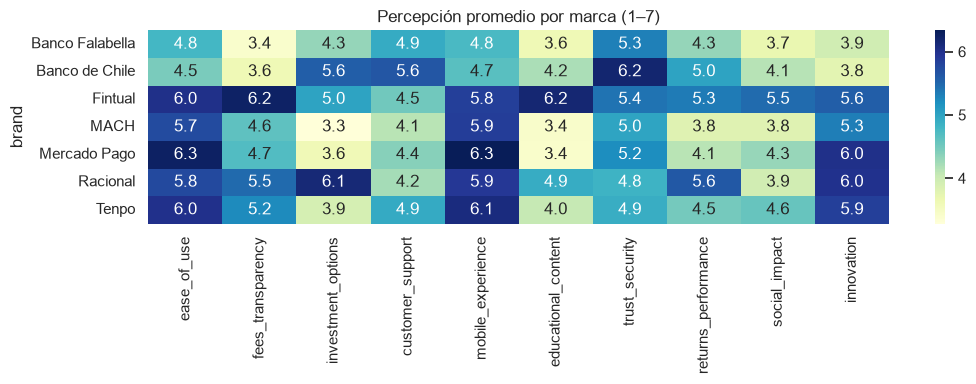

In [60]:
perception_columns_mapa = valor[valor["p Kruskal"] < 0.05].index.tolist()
perception_by_brand = fintual_percepcion.groupby("brand")[perception_columns_mapa].mean()   # NS/NR fuera del promedio
plt.figure(figsize=(11, 4))
sns.heatmap(perception_by_brand, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Percepción promedio por marca (1–7)"); plt.tight_layout(); plt.show()

In [64]:
### PCA: Dimensiones de valor percibido
scores = pca.fit_transform(data_scaled)

var = pd.DataFrame({"varianza explicada": pca.explained_variance_ratio_,
                    "acumulada": pca.explained_variance_ratio_.cumsum()}, index=["PC1", "PC2", "PC3"])
cargas = pd.DataFrame(pca.components_.T, index=perception_columns_mapa, columns=["PC1", "PC2", "PC3"])
display(var.round(3)); cargas.round(2).sort_values("PC1")

,varianza explicada,acumulada
PC1,0.52,0.52
PC2,0.33,0.84
PC3,0.10,0.94


,PC1,PC2,PC3
customer_support,-0.35,0.16,0.33
trust_security,-0.33,0.21,0.40
investment_options,-0.09,0.47,-0.46
returns_performance,0.04,0.52,-0.31
educational_content,0.14,0.50,0.06
social_impact,0.21,0.33,0.62
fees_transparency,0.39,0.25,0.07
mobile_experience,0.42,-0.11,0.06
ease_of_use,0.43,-0.08,0.14
innovation,0.43,-0.03,-0.08


### Nombrar las dimensiones (Con su carga):
PC1: Innovadores, Facil de usar, experiencia movil comoda, transparencias en sus tasas y comisiones. Poca confiaza en la seguridad y una persima atencion al clientes. -Digital Fintech vs Bancos tradicionales

PC2: Retornos altos, varias opciones para invertir, preocupados en la educacion financiera, un alto impacto socialmente. -Educacion e Inversion

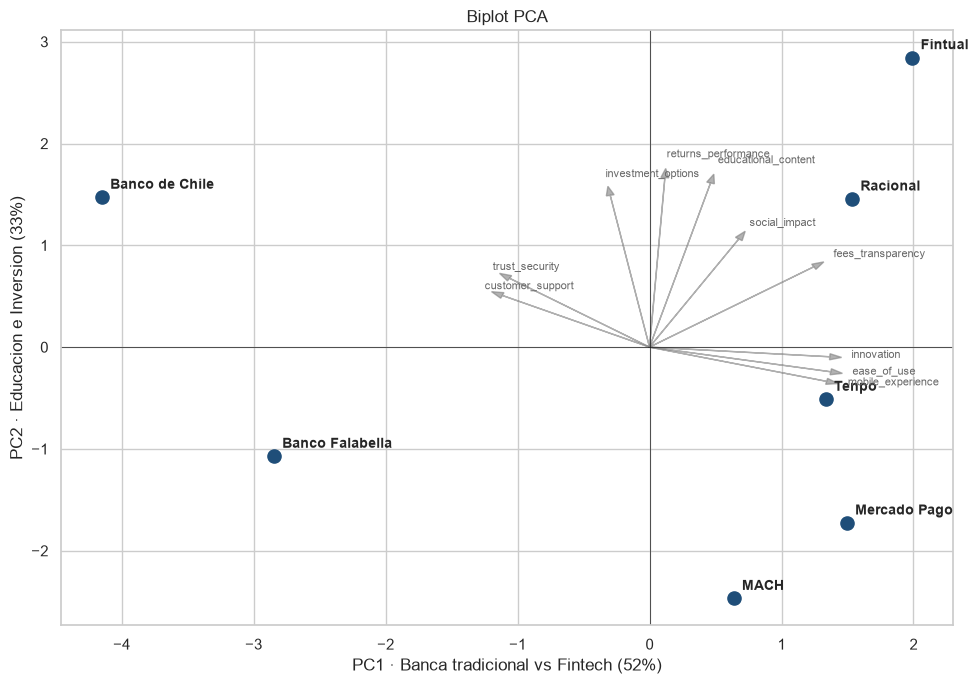

In [75]:
def biplot(scores, cargas, etiquetas, extra=None, titulo="Biplot PCA"):
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.scatter(scores[:, 0], scores[:, 1], s=90, color="#1f4e79")
    for i, m in enumerate(etiquetas):
        ax.annotate(m, (scores[i, 0], scores[i, 1]), xytext=(6, 6), textcoords="offset points", fontsize=10, weight="bold")
    k = 3.2
    for a in cargas.index:
        ax.arrow(0, 0, cargas.loc[a, "PC1"] * k, cargas.loc[a, "PC2"] * k, color="gray", alpha=.6, head_width=.06)
        ax.text(cargas.loc[a, "PC1"] * k * 1.12, cargas.loc[a, "PC2"] * k * 1.12, a, color="dimgray", fontsize=8)
    if extra is not None:
        for nombre, (x, y) in extra.iterrows():
            ax.scatter(x, y, marker="*", s=260, color="crimson")
            ax.annotate(f"Ideal: {nombre}", (x, y), xytext=(6, -12), textcoords="offset points", color="crimson", fontsize=9)
    ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
    ax.set_xlabel(f"PC1 · Banca tradicional vs Fintech ({pca.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 · Educacion e Inversion ({pca.explained_variance_ratio_[1]:.0%})")
    ax.set_title(titulo); plt.tight_layout(); plt.show()

biplot(scores, cargas, perception_by_brand.index)

In [77]:
d_orig = pdist(data_scaled)
Correlaciuon_PCA3 = np.corrcoef(d_orig, pdist(scores))[0, 1]
Correlaciuon_PCA2 = np.corrcoef(d_orig, pdist(scores[:, :2]))[0, 1]
print(f"Correlación distancias originales vs PCA 3 comp.: {Correlaciuon_PCA3:.3f} | vs PCA 2 comp. (el mapa): {Correlaciuon_PCA2:.3f}")

Correlación distancias originales vs PCA 3 comp.: 0.997 | vs PCA 2 comp. (el mapa): 0.962


La correlacion entre las ditancias originales con 3 componentes de PCA es de 0.997, lo que es mayor a 0.8 por lo que conserva bien las distancias originales. Con 2 componentes igual las conserva bien (0.962 > 0.08) pero es inferior a 3 componentes.

# MDS y comparación de métodos

Stress-1 de Kruskal: 0.116 | correlación distancias originales vs MDS: 0.958


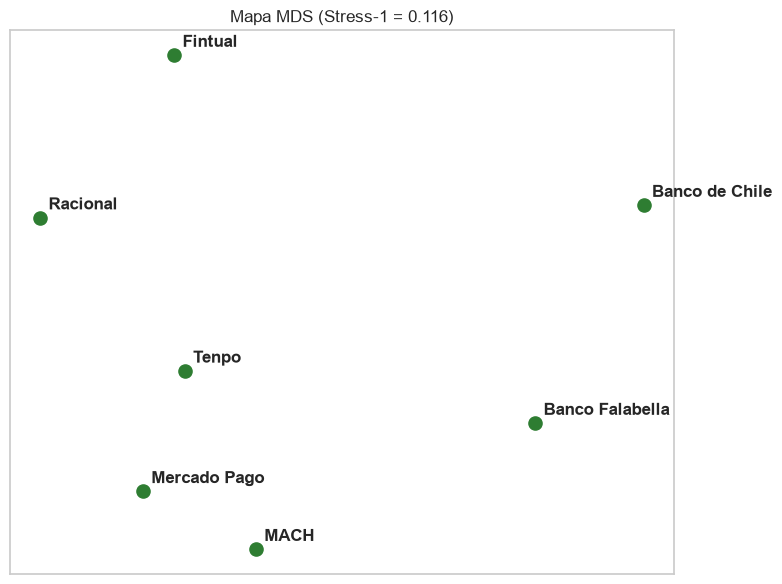

In [73]:
coordenadas = mds.fit_transform(data_scaled)
correlacion_mds = np.corrcoef(d_orig, pdist(coordenadas))[0, 1]
print(f"Stress-1 de Kruskal: {mds.stress_:.3f} | correlación distancias originales vs MDS: {correlacion_mds:.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(coordenadas[:, 0], coordenadas[:, 1], s=90, color="#2e7d32")
for i, m in enumerate(perception_by_brand.index):
    ax.annotate(m, coordenadas[i], xytext=(6, 6), textcoords="offset points", weight="bold")
ax.set_title(f"Mapa MDS (Stress-1 = {mds.stress_:.3f})"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

El stress-1 de Kruskal es de 0.116 lo que es menor a 0.20 y mayor a 0.10 por lo que es debil. la correlacion con las distancias originales es excelente (0.958 es mayor a 0.08) por lo que las conserva bien pero sigue siendo inferior a los de PCA.

#### Metodo recomendado
Para posicionar a la Fintual Card. Recomendamos usar PCA, porque tiene una mayor correlacion de distancias en comparacion con MDS debil. Adicionalmente en PCA podemos ver bien los atributos en lo que compite Fintual.

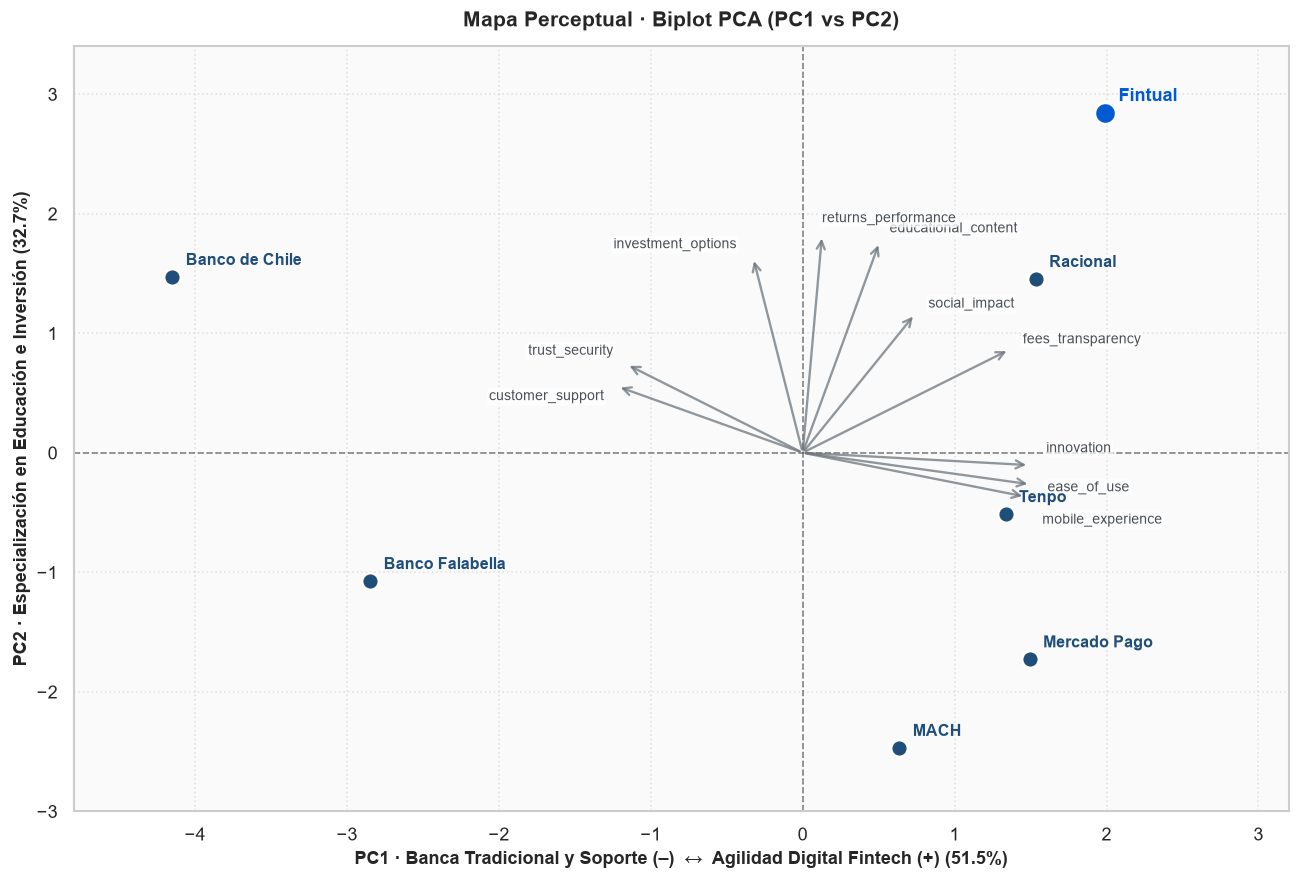

In [79]:
def biplot(scores, cargas, etiquetas, extra=None, titulo="Mapa Perceptual · Biplot PCA (PC1 vs PC2)"):
    fig, ax = plt.subplots(figsize=(11, 7.5), dpi=120)
    ax.set_facecolor("#fafafa")
    ax.grid(True, linestyle=":", alpha=0.5, color="#cccccc")

    # Ejes centrales
    ax.axhline(0, color="#555555", lw=1, ls="--", alpha=0.7)
    ax.axvline(0, color="#555555", lw=1, ls="--", alpha=0.7)

    # Ajustes finos de posición (dx, dy) para evitar que se encimen las etiquetas de atributos
    offsets_attr = {
        "innovation":          (10,  10),
        "ease_of_use":         (10,  -2),
        "mobile_experience":   (10, -14),
        "fees_transparency":   (8,    6),
        "social_impact":       (8,    6),
        "educational_content": (6,    8),
        "returns_performance": (0,   10),
        "investment_options":  (-10,  8),
        "trust_security":      (-8,   8),
        "customer_support":    (-8,  -6),
    }

    # Vectores de atributos (cargas)
    k = 3.5
    for a in cargas.index:
        x_vec = cargas.loc[a, "PC1"] * k
        y_vec = cargas.loc[a, "PC2"] * k
        ax.annotate(
            "", xy=(x_vec, y_vec), xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", color="#6c757d", lw=1.4, alpha=0.75)
        )
        dx, dy = offsets_attr.get(a, (6, 6))
        ha = "left" if x_vec >= 0 else "right"
        ax.annotate(
            a, (x_vec, y_vec), xytext=(dx, dy), textcoords="offset points",
            fontsize=8.5, color="#495057", ha=ha, va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75)
        )

    # Puntos y nombres de las marcas (destacando Fintual)
    for i, m in enumerate(etiquetas):
        es_fintual = (m == "Fintual")
        color_pto = "#005ad2" if es_fintual else "#1f4e79"
        size_pto = 160 if es_fintual else 100
        ax.scatter(
            scores[i, 0], scores[i, 1], s=size_pto, color=color_pto,
            edgecolors="white", linewidth=1.5, zorder=4
        )
        ax.annotate(
            m, (scores[i, 0], scores[i, 1]), xytext=(8, 7),
            textcoords="offset points", fontsize=10.5 if es_fintual else 9.5,
            weight="bold", color=color_pto, zorder=5
        )

    # Posición ideal / objetivo si se pasa el parámetro 'extra'
    if extra is not None:
        for nombre, (x, y) in extra.iterrows():
            ax.scatter(x, y, marker="*", s=280, color="crimson", zorder=6)
            ax.annotate(
                f"Objetivo: {nombre}", (x, y), xytext=(8, -12),
                textcoords="offset points", color="crimson", fontsize=9.5, weight="bold"
            )

    ax.set_xlim(-4.8, 3.2)
    ax.set_ylim(-3.0, 3.4)
    ax.set_xlabel(f"PC1 · Banca Tradicional y Soporte (–)  ↔  Agilidad Digital Fintech (+) ({pca.explained_variance_ratio_[0]:.1%})", fontsize=10.5, weight="bold")
    ax.set_ylabel(f"PC2 · Especialización en Educación e Inversión ({pca.explained_variance_ratio_[1]:.1%})", fontsize=10.5, weight="bold")
    ax.set_title(titulo, fontsize=12.5, weight="bold", pad=12)
    plt.tight_layout()
    plt.show()

biplot(scores, cargas, perception_by_brand.index)

#### Lectura marketing
Fintual esta en el mercado de las Finech con un alto nivel en educacion financiera y buen rendimiento en inversiones. Queda rezagada en opciones de ibversion y tiene todo el sentido del mundo. Fintual solo maneja 4 fondos mutuos:
- Risky Norris (Serie A, Serie APV, Serie Z)
- Moderate Pitt  (Serie A, Serie APV, Serie Z)
- Conservative Clooney (Serie A, Serie APV, Serie Z)
- Very Conservative Streep (Serie A)
Hay poca confianza en la seguridad, y hay un percepcion de un atencion al cliente baja. tambien se aleja de ser innovadora, no es tan intuitiva de usar y la experiencia movil no es tan buena. Fintual destaca en las siguientes fortaleza:
- Buen perfomance en sus retorno
- Contenido educacion (Fintualist) se preocuopan en la educacion financiera
- Impacto social
- Transparencias en sus tasas y comisiones

Los competidores mas cercanos a fintual son Racional por cercania y Banco de chile en competencia directa.